# MCX sem espaçador — código completo e independente

**Protocolos:** 660 nm: 3 J; 808 nm: 3 J; combinado: 6 J (3 J por emissão), todos em 30 s. Pigmentações: 3% e 30% de melanossomos. Os parâmetros físicos do notebook fornecido foram preservados, com músculo reduzido para 2 mm nesta versão. A geometria é a hipótese de dois núcleos de 600 µm em contato, com centros separados por 0,600 mm, descrita abaixo.


A malha padrão contém 118,8 milhões de voxels; requer GPU, memória e espaço em disco suficientes. Não há redução automática de resolução. As verificações locais de código não substituem a execução Monte Carlo e a análise de convergência.


**Exportação:** 16 figuras PNG a 600 dpi, cores originais, interfaces nos cortes laterais, tabelas CSV/TXT e dois ZIPs. Refazer uma figura substitui o arquivo de mesmo nome. A execução Monte Carlo requer GPU compatível.


# MCX sem espaçador: duas fibras de 600 µm
Cada fonte é um disco uniforme de raio 0,300 mm, área πr²/100 = 0,00282743 cm², em contato com a pele e incidência normal colimada. Os centros estão em x = −0,300 e +0,300 mm: distância de 0,600 mm é hipótese de núcleos encostados. A atribuição esquerda/direita de 660/808 nm é convencional.

Isolados: 3 J em 30 s, uma fonte ligada. Combinado: 6 J em 30 s, soma espacial das contribuições de 3 J de cada fonte, nas respectivas posições. Os discos não se sobrepõem na superfície nesta hipótese; a sobreposição nos tecidos decorre do transporte MCX. Área iluminada geométrica: 0,00282743 cm² nos isolados e 0,00565487 cm² no combinado. Substitui a hipótese anterior de 0,028 cm² e centros coincidentes.

Camadas: 0,10 mm de epiderme, 1,40 mm de derme, 2,00 mm de hipoderme e 2,00 mm de músculo. Malha uniforme de 0,1/6 mm, seis voxels na epiderme. As propriedades ópticas originais e suas limitações foram preservadas; não foram revalidadas nesta edição.


H é fluência em J/mm². U = μaH é densidade de energia absorvida em J/mm³; não é temperatura. Todos os mapas integrados XZ/YZ de fluência e absorção usam escala linear uniforme de profundidade e proporção física igual entre os eixos. A epiderme mantém sua espessura real no desenho. A malha e as energias não são alteradas.


## Execução completa
Execute as células na ordem, desde a instalação até o ZIP. Todos os dados usados são definidos aqui ou gerados nesta execução.


## 1 Instalando dependências


In [1]:
import subprocess, sys
subprocess.check_call([sys.executable,'-m','pip','install','-q','--upgrade','pmcx','numpy','matplotlib','psutil'])


0

## 2 Importando e checando a GPU


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import pmcx, json, csv, gc, shutil, psutil, tempfile
from pathlib import Path
from importlib.metadata import version
print('PMCX:',version('pmcx'))

# Explicação técnica exibida abaixo de cada figura.


# Exportação com margens para títulos, eixos, legendas e barras de cores.
def exportar_figura(fig, caminho, dpi):
    # Mantém identificação das fontes, tecidos e pigmentações na própria figura.
    caminho = Path(caminho)
    # Refazer uma figura substitui o mesmo arquivo, sem criar uma 17ª figura.
    exportar_origin(fig, caminho)
    fig.set_facecolor('white')
    fig.canvas.draw()
    fig.savefig(caminho, dpi=dpi, bbox_inches='tight', pad_inches=0.10)
    FIGURAS_GERADAS.add(caminho.stem)

# Exporta exatamente os pontos e matrizes usados em cada painel.
# TXT: primeira linha contém X, primeira coluna contém Y/Z; canto superior = NaN.
def exportar_origin(fig, caminho):
    from matplotlib.collections import QuadMesh
    pasta = Path(saida) / 'Origin' / Path(caminho).stem
    pasta.mkdir(parents=True, exist_ok=True)
    registros=[]
    def tabela(nome, colunas, valores):
        np.savetxt(pasta/nome, valores, delimiter=',', header=','.join(colunas),
                   comments='', fmt='%.17g', encoding='utf-8')
    def matriz(nome, xx, yy, valores, tipo):
        valores=np.asarray(np.ma.filled(valores,np.nan),dtype=float)
        m=np.empty((len(yy)+1,len(xx)+1));m[0,0]=np.nan
        m[0,1:]=xx;m[1:,0]=yy;m[1:,1:]=valores
        np.savetxt(pasta/(nome+'.txt'),m,delimiter='\t',fmt='%.17g')
        registros.append(dict(arquivo=nome+'.txt',tipo=tipo,linhas='Y ou profundidade',colunas='X',forma=list(valores.shape)))
    for i,ax in enumerate(fig.axes,1):
        if ax.get_label()=='<colorbar>':continue
        prefix=f'painel_{i:02d}'
        registros.append(dict(painel=i,titulo=ax.get_title(),xlabel=ax.get_xlabel(),ylabel=ax.get_ylabel(),
                             xscale=ax.get_xscale(),yscale=ax.get_yscale(),xlim=list(ax.get_xlim()),ylim=list(ax.get_ylim())))
        for j,line in enumerate(ax.lines,1):
            xx=np.asarray(line.get_xdata(),dtype=float); yy=np.asarray(line.get_ydata(),dtype=float)
            if xx.size!=yy.size:continue
            tabela(f'{prefix}_curva_{j:02d}.csv',['X','Y'],np.column_stack([xx,yy]))
            registros.append(dict(arquivo=f'{prefix}_curva_{j:02d}.csv',rotulo=line.get_label()))
        for j,patch in enumerate(ax.patches,1):
            if isinstance(patch,Circle):
                t=np.linspace(0,2*np.pi,361)
                tabela(f'{prefix}_circulo_{j:02d}.csv',['x_mm','y_mm'],
                       np.column_stack([patch.center[0]+patch.radius*np.cos(t),patch.center[1]+patch.radius*np.sin(t)]))
                registros.append(dict(circulo=j,centro=list(patch.center),raio_mm=patch.radius))
        barras=[b for cont in ax.containers if hasattr(cont,'patches') for b in cont.patches]
        if barras:
            tabela(f'{prefix}_barras.csv',['x_centro','energia_J','largura'],
                   np.array([[b.get_x()+b.get_width()/2,b.get_height(),b.get_width()] for b in barras]))
        mapas=[]
        for im in ax.images:
            v=im.get_array();left,right,bottom,top=im.get_extent();nr,nc=v.shape
            xx=np.linspace(left+(right-left)/(2*nc),right-(right-left)/(2*nc),nc)
            yy=np.linspace(top+(bottom-top)/(2*nr),bottom-(bottom-top)/(2*nr),nr) if im.origin=='upper' else np.linspace(bottom+(top-bottom)/(2*nr),top-(top-bottom)/(2*nr),nr)
            # A razão usa extent entre centros no código original: mantém os eixos físicos reais.
            if Path(caminho).stem=='H_razao_pigmentacao_XY':xx,yy=XT,YT
            mapas.append((xx,yy,v))
        for coll in ax.collections:
            if isinstance(coll,QuadMesh):
                co=coll.get_coordinates();xx=(co[0,:-1,0]+co[0,1:,0])/2
                yy=(co[:-1,0,1]+co[1:,0,1])/2
                mapas.append((xx,yy,np.asarray(coll.get_array()).reshape(len(yy),len(xx))))
        for j,(xx,yy,v) in enumerate(mapas,1):
            base=f'{prefix}_mapa_{j:02d}'
            logaritmico=Path(caminho).stem not in ['volume_simulado','H_razao_pigmentacao_XY']
            matriz(base+'_desenhado',xx,yy,v,'log10 do campo' if logaritmico else 'razao ou ID do tecido')
            if logaritmico:
                # Campo bruto exportado separadamente abaixo, pois o desenho usa piso 1e-30.
                matriz(base+'_inverso_log10',xx,yy,10.**np.asarray(v),'10**log10(max(campo,1e-30)); contém piso visual')
    (pasta/'painéis.json').write_text(json.dumps(registros,ensure_ascii=False,indent=2),encoding='utf-8')


# Tipografia para impressão; não modifica os resultados ópticos.
plt.rcParams.update({'font.size':15, 'axes.titlesize':17, 'axes.labelsize':17,
                     'xtick.labelsize':14, 'ytick.labelsize':14, 'legend.fontsize':13,
                     'lines.linewidth':2.2, 'pdf.fonttype':42, 'ps.fonttype':42})


PMCX: 0.7.1


## 3 Definindo os parâmetros do estudo


In [3]:
# 2. Aparelho e hipóteses geométricas
POTENCIA_POR_LAMBDA_W = 0.100
TEMPO_S = 30.0
ENERGIA_POR_LAMBDA_J = POTENCIA_POR_LAMBDA_W * TEMPO_S
ENERGIA_COMBINADA_J = 2 * ENERGIA_POR_LAMBDA_J
DISTANCIA_ESPACADOR_MM = 0.0
DIAMETRO_UTIL_FIBRA_MM = 0.600  # manual; não é a separação medida dos centros
AREA_CONJUNTA_CM2 = 2 * np.pi * (DIAMETRO_UTIL_FIBRA_MM/2)**2 / 100  # área geométrica calculada para dois discos sem sobreposição
AREA_POR_FIBRA_CM2 = np.pi * (DIAMETRO_UTIL_FIBRA_MM/2)**2 / 100
AREA_PELE_FABRICANTE_CM2 = AREA_POR_FIBRA_CM2  # alias de compatibilidade; área calculada, não medida
MODELO_FONTE = "duas_fibras_600um_contato_colimadas"
# Hipótese: discos uniformes correspondentes às seções dos núcleos em contato com a pele.
# Área calculada a partir do diâmetro útil de 600 µm; contato é hipótese.
# MCX disk e raio em voxels: https://github.com/fangq/mcx/blob/master/mcxlab/mcxlab.m
# Centros distintos; distância ajustável e não medida na foto.
SEPARACAO_PRINCIPAL_MM = 0.600  # hipótese: núcleos encostados, não medição
ORIGEM_SEPARACAO = "fibras_encostadas_hipotese"
if not np.isfinite(SEPARACAO_PRINCIPAL_MM) or SEPARACAO_PRINCIPAL_MM < 0:
    raise ValueError('Separação inválida.')

RAIO_MM = np.sqrt(100 * AREA_PELE_FABRICANTE_CM2 / np.pi)
assert np.isclose(np.pi * RAIO_MM**2 / 100, AREA_PELE_FABRICANTE_CM2)
AREA_MM2 = float(np.pi * RAIO_MM**2)
AREA_CM2 = AREA_MM2 / 100
DIVERGENCIA_TOTAL_AR_RAD = 0.45
SEMIANGULO_AR_RAD = DIVERGENCIA_TOTAL_AR_RAD / 2
USAR_DIVERGENCIA = False  # a área define a iluminação no plano da pele; propagação no ar não é resolvida
RUN_CHECKS = True
EXECUTAR_SIMULACOES = True  # execução completa; não reutiliza resultados externos
REFAZER_FIGURAS = False
DPI = 600  # resolução de impressão; não altera a malha MCX
CAMADAS = ['epiderme','derme','hipoderme','musculo']
# Cenário principal: separação hipotética configurada acima.
SEPARACOES_MM = [SEPARACAO_PRINCIPAL_MM]
MODELO_ESPALHAMENTO = 'cassemiro'  # equação 6 e tabela 2 do artigo
MODELO_ABSORCAO_EPI = 'cassemiro_composicao_tabela1_biblioteca_publica'
PELES = {'clara_3pct': 0.03, 'escura_30pct': 0.30}
EPI_MM, DERME_MM, HIPO_MM, MUSCULO_MM = 0.100, 1.400, 2.000, 2.000
VOXELS_EPIDERME = 6
VOXEL_MM = EPI_MM / VOXELS_EPIDERME
NX = NY = int(round(10.0/VOXEL_MM))  # domínio lateral mantido em 10 mm
NPHOTON = 10_000_000
SEED = 12345
GPUID = 1  # primeiro dispositivo do MCX
TEND_S = TSTEP_S = 5e-9  # tempo óptico de voo; diferente dos 30 s de exposição
ENERGIA_ISOLADO_J = 3.0
TEMPO_ISOLADO_S = ENERGIA_ISOLADO_J / POTENCIA_POR_LAMBDA_W
# Pasta exclusiva: impede misturar arquivos com execuções anteriores.
saida = Path(tempfile.mkdtemp(prefix='resultados_MCX_sem_espacador_fibras600um_3J_6J_', dir=Path.cwd()))
FIGURAS_GERADAS = set()

# Área iluminada: um disco no isolado, dois discos sem sobreposição no combinado.
AREAS_PROTOCOLOS_CM2 = {'660': AREA_CM2, '808': AREA_CM2, '660+808': 2*AREA_CM2}
assert SEPARACAO_PRINCIPAL_MM >= 2*RAIO_MM
assert set(PELES)=={'clara_3pct','escura_30pct'}
assert np.isclose(PELES['clara_3pct'],.03) and np.isclose(PELES['escura_30pct'],.30)
assert np.isclose(AREA_CM2, np.pi*.3**2/100)
assert np.isclose(AREAS_PROTOCOLOS_CM2['660+808'], 2*AREA_CM2)
print('Área geométrica iluminada por protocolo (cm²):', AREAS_PROTOCOLOS_CM2)
print('Diâmetro circular equivalente (não somar):',2*RAIO_MM,'mm')
print('Duas fontes distintas; distância de 0,600 mm entre centros é hipótese.')
print('Isolados:',ENERGIA_ISOLADO_J,'J em',TEMPO_ISOLADO_S,'s; combinado: 6 J em 30 s.')
print(f'Resolução: {VOXEL_MM*1000:.6g} µm; epiderme: {VOXELS_EPIDERME} voxels; profundidade: 5,5 mm')


Área geométrica iluminada por protocolo (cm²): {'660': 0.002827433388230814, '808': 0.002827433388230814, '660+808': 0.005654866776461628}
Diâmetro circular equivalente (não somar): 0.6 mm
Duas fontes distintas; distância de 0,600 mm entre centros é hipótese.
Isolados: 3.0 J em 30.0 s; combinado: 6 J em 30 s.
Resolução: 16.6667 µm; epiderme: 6 voxels; profundidade: 5,5 mm


## 4 Propriedades ópticas por camada


In [4]:
# Propriedades transcritas das tabelas de Entradas_MCX_anisotropia_Haugen.docx.
# Valores arredondados exatamente como apresentados no Word; fontes e limitações abaixo.
# Entradas ópticas documentadas na tabela Word.
# g muscular: Haugen et al. (2023), Dataset 1, DOI 10.6084/m9.figshare.22216954.
# Aba Rat Anisotropy, C79 (660 nm) e C116 (808 nm): músculo de rato.
# μs muscular recalculado com μs′ de Cassemiro, eq. 6/tabela 2, dividido por (1-g).
PROPRIEDADES_WORD = {(660, 'clara_3pct'): [[0.808534, 26.389351, 0.8114, 1.4], [0.065484, 16.779345, 0.8114, 1.4], [0.065484, 8.095626, 0.8114, 1.34], [0.000659, 16.695435, 0.948017, 1.4]], (660, 'escura_30pct'): [[8.083395, 26.389351, 0.8114, 1.4], [0.065484, 16.779345, 0.8114, 1.4], [0.065484, 8.095626, 0.8114, 1.34], [0.000659, 16.695435, 0.948017, 1.4]], (808, 'clara_3pct'): [[0.413277, 27.011978, 0.85432, 1.4], [0.050889, 16.725998, 0.85432, 1.4], [0.04, 9.148403, 0.85432, 1.34], [0.001574, 15.20434, 0.953797, 1.4]], (808, 'escura_30pct'): [[4.122015, 27.011978, 0.85432, 1.4], [0.050889, 16.725998, 0.85432, 1.4], [0.04, 9.148403, 0.85432, 1.34], [0.001574, 15.20434, 0.953797, 1.4]]}
FONTE_WORD = 'Entradas ópticas para a simulação MCX em 660 e 808 nm\nTabela de entradas do modelo de quatro camadas para os cenários de pele clara (3%) e escura (30% de melanossomos). São parâmetros publicados, calculados ou interpolados conforme as fontes indicadas. \nNo MCX, a linha de propriedades de cada tecido deve seguir [μa, μs, g, n], com μa e μs em mm⁻¹. Use o espalhamento total μs apresentado abaixo. As espessuras são entradas da geometria, separadas dessa linha.\n660 nm\nOrigem: d — Mignon; pigmentação — Regan; μa epidérmico — composição de Cassemiro e entradas MCmatlab; μa dérmico/adiposo — interpolação de Shimojo; μs e g — cálculos com Cassemiro; n — tabela 2 de Cassemiro. Detalhes na próxima página. Músculo: μa e μs′ calculados com Cassemiro e espectros MCmatlab; g medido em músculo de rato por Haugen et al. (2023), Dataset 1, aba Rat Anisotropy, coluna C; μs recalculado com esse g. n = 1,40 conforme Cassemiro.\n808 nm\nOrigem: d — Mignon; pigmentação — Regan; μa epidérmico — composição de Cassemiro e entradas MCmatlab; μa dérmico/adiposo — interpolação de Shimojo; μs e g — cálculos com Cassemiro; n — tabela 2 de Cassemiro. Detalhes na próxima página. Músculo: μa e μs′ calculados com Cassemiro e espectros MCmatlab; g medido em músculo de rato por Haugen et al. (2023), Dataset 1, aba Rat Anisotropy, coluna C; μs recalculado com esse g. n = 1,40 conforme Cassemiro.\n\nOrigem e método de obtenção das entradas\nLegenda: d = espessura; μa = coeficiente de absorção; μs = coeficiente de espalhamento total; g = fator de anisotropia; n = índice de refração. g e n não têm unidade. Hipoderme representa o tecido adiposo subcutâneo do modelo.\nEspessuras. Mignon et al. (2018), seção 2.1: epiderme 100 µm (0,10 mm), derme 1,40 mm e tecido adiposo 2,00 mm. São espessuras adotadas em simulação. As espessuras das três primeiras camadas foram mantidas de Mignon. Nesta versão adotou-se músculo de 2,00 mm como escolha geométrica do presente modelo; profundidade total de 5,50 mm. A espessura de 2 mm não é atribuída ao artigo de Cassemiro. Essa escolha não é uma espessura anatômica universal nem reproduz integralmente a geometria facial do artigo.\nPigmentação. Regan et al. (2017), figura 3: cenários clara 3% (M = 0,03) e escura 30% (M = 0,30). São frações de melanossomos do modelo, sem conversão individual dos valores de ITA.\nAbsorção da epiderme. Calculada em cm⁻¹ por μa = 0,60 μa,água + 0,15 μa,gordura + M μa,melanossomos; dividir por 10 para mm⁻¹. Composição: Cassemiro (2024), tabela 1 e equações 2–3. Entradas espectrais: MCmatlab, spectralLIB.mat, ramo Release, arquivo conferido nesta sessão.\nAbsorção da derme e hipoderme. Interpolação linear dos valores médios de Shimojo et al. (2020), tabela 3. Para 660 nm: pontos 632 e 694 nm (0,07 e 0,06 mm⁻¹ nas duas camadas). Para 808 nm: pontos 800 e 980 nm (derme 0,05 e 0,07; gordura 0,04 e 0,04 mm⁻¹). A interpolação é uma escolha do modelo; não é uma medição em 660/808 nm.\nEspalhamento total. Cassemiro, equação 6: μs′ = a (λ/500)⁻ᵇ, em cm⁻¹. Parâmetros (a; b) da tabela 2: epiderme (68,7; 1,161), derme (45,3; 1,292), gordura (18,4; 0,672). Dividir μs′ por 10 e calcular μs = μs′/(1−g). λ é o comprimento de onda em nm.\nAnisotropia e refração. Cassemiro, equação 7: g = 0,62 + 0,00029 λ. A aplicação dessa relação à gordura é uma hipótese adotada pelos autores. n é copiado da tabela 2: 1,40 para epiderme/derme e 1,34 para gordura.\nMúsculo. A absorção permanece calculada pela composição de Cassemiro et al. (2024), tabela 1: HbO₂ = Hb = 0,50 µM e água 70%, com espectros MCmatlab. Não é uma medição das amostras. O espalhamento reduzido é calculado pela equação 6 e tabela 2: μs′ = 11,6(λ/500)⁻¹·⁰⁴⁵/10, em mm⁻¹, dentro da faixa de 620–1000 nm informada para esse ajuste. A anisotropia é retirada diretamente de Haugen et al. (2023), Dataset 1, aba Rat Anisotropy: g = 0,9480171002957918 em 660 nm (C79) e 0,953797103718739 em 808 nm (C116). São dados experimentais de músculo de rato; sua adoção no modelo humano é uma aproximação entre espécies. Não há interpolação nem extrapolação desses dois valores de g. μs = μs′/(1−g), usando os valores completos antes do arredondamento. n = 1,40 conforme Cassemiro. As entradas musculares são iguais nos dois cenários de pigmentação.\nLimitações das entradas\nμa,gordura = 0,0001 cm⁻¹ na biblioteca é uma entrada de preenchimento já identificada, sem confirmação como medida de gordura pura em 660/808 nm. A absorção epidérmica é condicionada a essa entrada. M = 0,30 excede a faixa de 0,01–0,20 da tabela 1 de Cassemiro. A implementação não reproduz exatamente a tabela 3 daquele artigo. Estes valores permitem executar o modelo declarado, mas não devem ser apresentados como medidas exatas ou parâmetros validados das suas amostras. A equação muscular de g limitada a 500–800 nm não é utilizada nesta versão. Os valores de Haugen provêm de ratos e não são medições de músculo humano. A interpolação de μa dérmico/adiposo permanece identificada; a aplicação de g da derme à gordura continua sendo uma hipótese de Cassemiro. Portanto, a tabela reúne medições, cálculos e hipóteses documentadas, não apenas medições diretas. A camada muscular de 2 mm é finita e requer teste da influência da fronteira inferior.\nReferências\nMignon et al. 2018. DOI: 10.1364/BOE.9.000852.\nRegan et al. 2017. DOI: 10.1364/BOE.8.005708.\nCassemiro et al. 2024. DOI: 10.3390/photonics11111038.\nShimojo et al. 2020. DOI: 10.1117/1.JBO.25.4.045002.\nMCmatlab. https://github.com/ankrh/MCmatlab/blob/Release/helperfuncs/spectralLIB.mat (consulta em 10/10/2026).\nHaugen EJ, Throckmorton GA, Walter AB, Mahadevan-Jansen A, Baba JS. Measurement of rat and human tissue optical properties for improving the optical detection and visualization of peripheral nerves. Biomedical Optics Express, 2023. Artigo: https://pmc.ncbi.nlm.nih.gov/articles/PMC10278628/. Dataset 1 Optical Properties: https://doi.org/10.6084/m9.figshare.22216954. Arquivo conferido: Optical_Properties_Fat_Muscle_Tendon_Nerve(2).xlsx; Rat Anisotropy, A79/C79 e A116/C116.'
linhas=[]
for (lam,pele),p in PROPRIEDADES_WORD.items():
    for camada,val in zip(CAMADAS,p):
        linhas.append(dict(lambda_nm=lam,pele=pele,camada=camada,mua_mm_1=val[0],mus_mm_1=val[1],g=val[2],n=val[3]))
with (saida/'propriedades_do_Word.csv').open('w',newline='',encoding='utf-8') as arq:
    w=csv.DictWriter(arq,fieldnames=list(linhas[0]));w.writeheader();w.writerows(linhas)
(saida/'origem_valores_Word.txt').write_text(FONTE_WORD,encoding='utf-8')
print('Entradas ópticas copiadas exatamente das tabelas do Word.')

assert set(PROPRIEDADES_WORD)=={(lam,pe) for lam in [660,808] for pe in PELES}
print('Entradas conferidas: ambas as pigmentações em 660 e 808 nm.')


Entradas ópticas copiadas exatamente das tabelas do Word.
Entradas conferidas: ambas as pigmentações em 660 e 808 nm.


## 5 Definindo o volume vol


Um campo float32: 0.44 GiB; RAM estimada: 1.5 GiB
Voxels por camada: [  6  84 120 120] ; espessuras (mm): [0.1 1.4 2.  2. ]


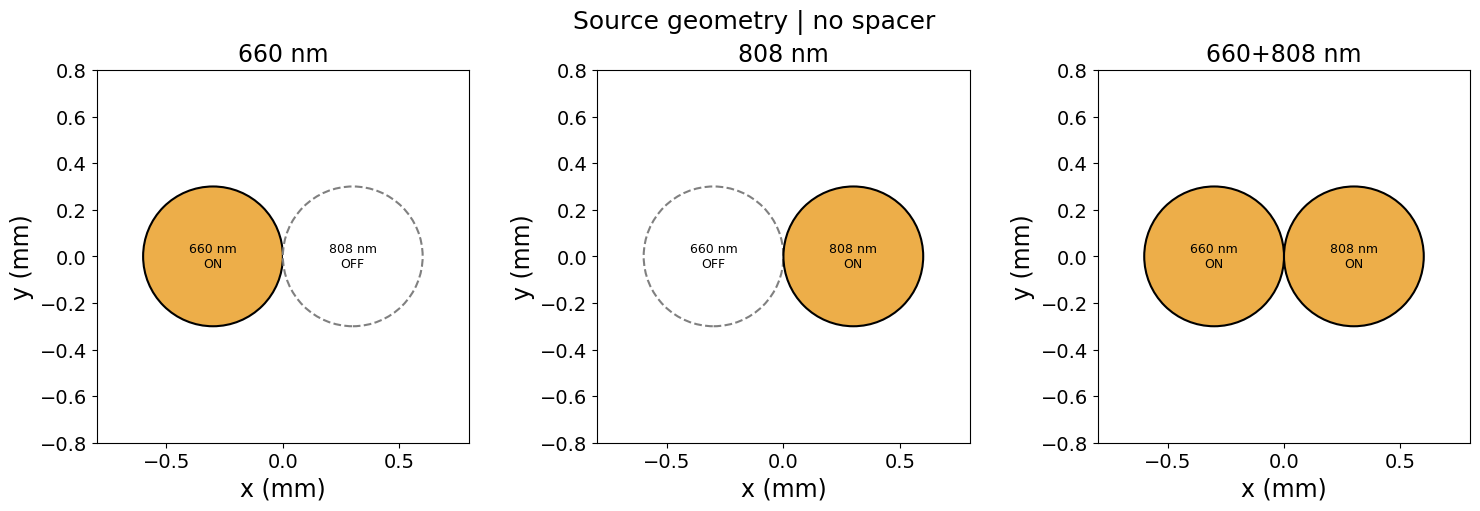

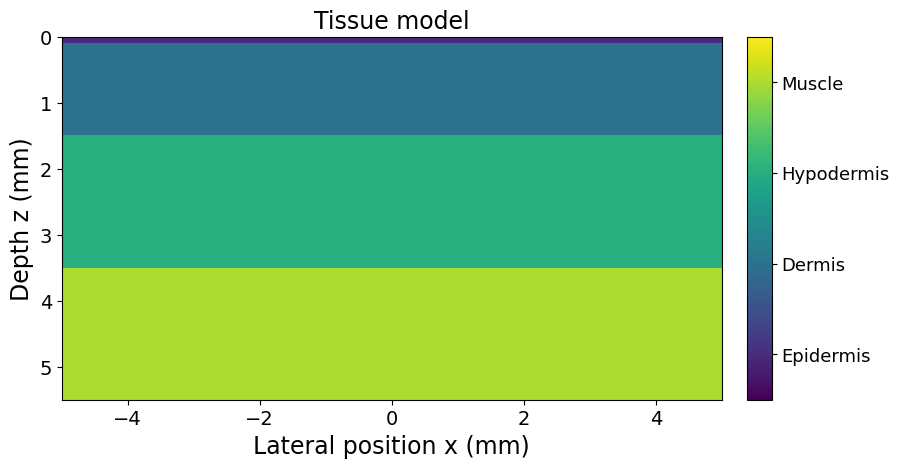

In [5]:
# 4. Volume e mapa geométrico no plano da pele
esp = np.array([EPI_MM,DERME_MM,HIPO_MM,MUSCULO_MM])
nv = np.rint(esp/VOXEL_MM).astype(int)
assert np.allclose(nv*VOXEL_MM,esp)
limites=np.cumsum(nv)
NZ=int(limites[-1])
# Malha padrão: 600 × 600 × 330, 118,8 milhões de voxels.
# Estimativa conservadora de RAM; VRAM também precisa comportar o vol e o campo MCX.
estimativa_ram=NX*NY*NZ*14
print(f'Um campo float32: {NX*NY*NZ*4/2**30:.2f} GiB; RAM estimada: {estimativa_ram/2**30:.1f} GiB')
if psutil.virtual_memory().available < estimativa_ram*1.15:
    raise MemoryError('Use runtime com mais RAM ou altere explicitamente VOXEL_MM para 0.025. A resolução não é reduzida automaticamente.')
vol=np.full((NX,NY,NZ),4,dtype=np.uint8)
vol[:,:,limites[1]:limites[2]]=3
vol[:,:,:limites[0]]=1
vol[:,:,limites[0]:limites[1]]=2
print('Voxels por camada:',nv,'; espessuras (mm):',nv*VOXEL_MM)

# A geometria usa a mesma separação e o mesmo raio da configuração MCX.
# Eixo x escolhido para conter os dois centros no corte XZ.
# Superior/inferior na foto não identifica qual comprimento de onda sai de cada núcleo.
def geometria_fibras(protocolos, arquivo):
    fig, axs = plt.subplots(1,len(protocolos),figsize=(5*len(protocolos),5),squeeze=False,layout='constrained')
    for ax,p in zip(axs.flat,protocolos):
        for lam,xc in [('660',-SEPARACAO_PRINCIPAL_MM/2),('808',SEPARACAO_PRINCIPAL_MM/2)]:
            ativa = p=='660+808' or p==lam
            ax.add_patch(Circle((xc,0),RAIO_MM,facecolor='#edae49' if ativa else 'white',edgecolor='black' if ativa else 'grey',ls='-' if ativa else '--',lw=1.5))
            ax.text(xc,0,f'{lam} nm\n'+('ON' if ativa else 'OFF'),ha='center',va='center',fontsize=9)
        alcance=SEPARACAO_PRINCIPAL_MM/2+RAIO_MM+.2
        ax.set(xlim=(-alcance,alcance),ylim=(-alcance,alcance),xlabel='x (mm)',ylabel='y (mm)',title=f'{p} nm')
        ax.set_aspect('equal')
    fig.suptitle('Source geometry | no spacer')
    exportar_figura(fig,saida/arquivo,DPI)
    plt.show();plt.close(fig)
geometria_fibras(['660','808','660+808'],'geometria_spots.png')
# Corte geométrico: superfície em cima, coordenadas físicas reais.
x=(np.arange(NX)+.5-NX/2)*VOXEL_MM
z=(np.arange(NZ)+.5)*VOXEL_MM
fig,ax=plt.subplots(figsize=(10,6))
fig.subplots_adjust(left=.12,right=.78,bottom=.15,top=.90)
im=ax.imshow(vol[:,NY//2,:].T,origin='upper',interpolation='nearest',aspect='equal',
             extent=[-NX*VOXEL_MM/2,NX*VOXEL_MM/2,float(esp.sum()),0],
             cmap='viridis',vmin=.5,vmax=4.5)
ax.set(xlabel='Lateral position x (mm)',ylabel='Depth z (mm)',title='Tissue model')
ax.set_yticks(np.arange(0.,np.floor(esp.sum())+1.,1.))
# Posição calculada após o ajuste de aspecto: barra com altura idêntica ao mapa.
fig.canvas.draw()
posicao=ax.get_position()
cax=fig.add_axes([posicao.x1+.025,posicao.y0,.025,posicao.height],label='<colorbar>')
cb=fig.colorbar(im,cax=cax,ticks=[1,2,3,4])
cb.ax.set_yticklabels(['Epidermis','Dermis','Hypodermis','Muscle'])
cb.ax.tick_params(labelsize=13)
exportar_figura(fig,saida/'volume_simulado.png',DPI)
plt.show();plt.close(fig)


## 6 Configuração explícita cfg e execução Monte Carlo


In [6]:
# O laço apenas repete a mesma configuração para 4 casos (2 pigmentações × 2 comprimentos).
# Campos volumétricos são salvos e liberados antes do próximo caso.
resumo=[]
dados={}
if EXECUTAR_SIMULACOES:
    gpu_info=pmcx.gpuinfo()
    print('GPUs encontradas:',gpu_info)
    if not gpu_info:
        raise RuntimeError('Selecione uma GPU no Colab antes de simular.')
    necessario=NX*NY*NZ*4*16  # margem para campos e temporários sem presumir compressão
    if shutil.disk_usage(saida).free<necessario:
        raise OSError(f'Reserve pelo menos {necessario/2**30:.1f} GiB livres.')
    for pele,f in PELES.items():
        for lambda_nm in [660,808]:
            d_mm=SEPARACAO_PRINCIPAL_MM
            deslocamento_mm=-d_mm/2 if lambda_nm==660 else d_mm/2
            cfg={
                'nphoton':NPHOTON,
                'vol':vol,
                'unitinmm':VOXEL_MM,
                'tstart':0.,
                'tend':TEND_S,
                'tstep':TSTEP_S,
                'srcpos':[NX/2+deslocamento_mm/VOXEL_MM,NY/2,-1e-6],
                'srcdir':[0.,0.,1.,0.],
                'srctype':'disk',
                'srcparam1':[RAIO_MM/VOXEL_MM,0.,0.,0.],
                'prop':np.array([[0.,0.,1.,1.],*PROPRIEDADES_WORD[(lambda_nm,pele)]],dtype=float),
                'issrcfrom0':1,
                'maxvoidstep':max(1000,int(np.ceil(2*DISTANCIA_ESPACADOR_MM/VOXEL_MM))+10),
                'voidtime':1,
                'autopilot':1,
                'gpuid':GPUID,
                'isreflect':1,
                'isspecular':1,
                'issavedet':0,
                'isnormalized':1,
                'outputtype':'fluence',
                'seed':SEED+(0 if lambda_nm==660 else 1),
            }
            # Cada fonte circular ocupa sua própria posição imediatamente antes da pele.
            # Não há percurso no ar resolvido nem modelagem da óptica interna da ponteira.
            # Considera a interface externa e a refração/Fresnel.
            if USAR_DIVERGENCIA:
                u=np.linspace(0.,1.,512)
                cfg['angleinvcdf']=(np.arccos(1-u*(1-np.cos(SEMIANGULO_AR_RAD)))/np.pi).astype(np.float32)
            if RUN_CHECKS:
                assert np.isclose(cfg['srcpos'][2],-1e-6)
                assert d_mm >= 2*RAIO_MM
                assert np.isclose(AREA_CM2, AREA_PELE_FABRICANTE_CM2)
                assert abs(deslocamento_mm)+RAIO_MM+DISTANCIA_ESPACADOR_MM*np.tan(SEMIANGULO_AR_RAD)<NX*VOXEL_MM/2
                assert np.allclose(nv*VOXEL_MM,esp) and len(nv)==4
                assert cfg['prop'].shape==(5,4) and np.isfinite(cfg['prop']).all()
                assert abs(deslocamento_mm)+RAIO_MM<NX*VOXEL_MM/2
                assert np.isclose(TEMPO_ISOLADO_S*POTENCIA_POR_LAMBDA_W,ENERGIA_ISOLADO_J)
                if USAR_DIVERGENCIA:
                    assert np.all(np.diff(cfg['angleinvcdf'])>=0)
                    assert np.isclose(cfg['angleinvcdf'][-1]*np.pi,SEMIANGULO_AR_RAD)
            print(f'MCX: {pele}, {lambda_nm} nm, {ENERGIA_ISOLADO_J:g} J',flush=True)
            res=pmcx.run(cfg)
            # A chave continua sendo flux, mesmo escolhendo outputtype=fluence.
            fluence=np.asarray(res['flux'],dtype=np.float32)
            if fluence.ndim==4:
                if fluence.shape[3]!=1:raise RuntimeError('Esperada uma janela óptica.')
                fluence=fluence[:,:,:,0]
            if fluence.shape!=vol.shape:raise RuntimeError('Dimensões incompatíveis.')
            # MCX fluence normalizada é por unidade de energia; escala pelo protocolo.
            fluence*=ENERGIA_ISOLADO_J
            H=fluence
            U=np.empty_like(H)
            for a,b,rotulo in zip([0,*limites[:-1]],limites,range(1,5)):
                np.multiply(H[:,:,a:b],cfg['prop'][rotulo,0],out=U[:,:,a:b])
            energia_camadas=np.array([float(U[:,:,a:b].sum(dtype=np.float64)*VOXEL_MM**3)
                                     for a,b in zip([0,*limites[:-1]],limites)])
            Eabs=float(energia_camadas.sum())
            if not np.isfinite(H).all() or H.min()<0 or not 0<Eabs/ENERGIA_ISOLADO_J<=1.02:
                raise RuntimeError('Saída inválida ou absorção fora do balanço esperado.')
            meta=dict(pele=pele,lambda_nm=lambda_nm,energia_incidente_J=ENERGIA_ISOLADO_J,
                tempo_s=TEMPO_ISOLADO_S,potencia_W=POTENCIA_POR_LAMBDA_W,
                camadas=CAMADAS,espessuras_mm=esp.tolist(),voxel_mm=VOXEL_MM,
                modelo_fonte=MODELO_FONTE,diametro_fonte_mm=2*RAIO_MM,area_por_spot_cm2=AREA_CM2,area_conjunta_cm2=AREA_CONJUNTA_CM2,
                separacao_hipotetica_mm=d_mm,origem_separacao="fibras_encostadas_hipotese",distancia_espacador_mm=DISTANCIA_ESPACADOR_MM,
                divergencia_total_ar_rad=DIVERGENCIA_TOTAL_AR_RAD if USAR_DIVERGENCIA else 0.,
                perfil_angular_hipotese='incidencia_normal_colimada_na_pele',angulo_total_interpretado=True,
                fonte_z_voxel=-1e-6,area_fonte_modelo_cm2=AREA_PELE_FABRICANTE_CM2,perfil_espacial_hipotese='discos_uniformes_separados_contato',percurso_ar_simulado=False,energia_absorvida_J=Eabs,modelo_termico=False,
                pmcx_version=version('pmcx'))
            pre=f'd_{d_mm:.3f}mm_{pele}_{lambda_nm}nm'
            np.savez_compressed(saida/f'{pre}.npz',fluencia_J_mm2=H,energia_absorvida_J_mm3=U,
                propriedades=cfg['prop'],metadados_json=json.dumps(meta,ensure_ascii=False))
            (saida/f'{pre}_mcx_stat.json').write_text(json.dumps(res.get('stat',{}),
                default=lambda a:a.tolist() if hasattr(a,'tolist') else str(a)),encoding='utf-8')
            # Somente o corte central e perfis ficam em memória para gráficos.
            dados[(pele,str(lambda_nm))]=dict(H=H[:,NY//2:NY//2+1,:].copy(),U=U[:,NY//2:NY//2+1,:].copy(),
                media_H=H.mean(axis=(0,1),dtype=np.float64),media_U=U.mean(axis=(0,1),dtype=np.float64),
                energia_camadas=energia_camadas,Eabs=Eabs)
            del H,U,fluence,res;gc.collect()


GPUs encontradas: [{'name': 'Tesla T4', 'id': 1, 'devcount': 1, 'major': 7, 'minor': 5, 'globalmem': 15637086208, 'constmem': 65536, 'sharedmem': 49152, 'regcount': 65536, 'clock': 1590000, 'sm': 40, 'core': 2560, 'autoblock': 64, 'autothread': 81920, 'maxgate': 0}]
MCX: clara_3pct, 660 nm, 3 J
nphoton: 1e+07
tstart: 0
tstep: 5e-09
tend: 5e-09
isreflect: 1
isnormalized: 1
issrcfrom0: 1
autopilot: 1
unitinmm: 0.0166667
voidtime: 1
isspecular: 1
maxvoidstep: 1000
issavedet: 0
MCX: clara_3pct, 808 nm, 3 J
nphoton: 1e+07
tstart: 0
tstep: 5e-09
tend: 5e-09
isreflect: 1
isnormalized: 1
issrcfrom0: 1
autopilot: 1
unitinmm: 0.0166667
voidtime: 1
isspecular: 1
maxvoidstep: 1000
issavedet: 0
MCX: escura_30pct, 660 nm, 3 J
nphoton: 1e+07
tstart: 0
tstep: 5e-09
tend: 5e-09
isreflect: 1
isnormalized: 1
issrcfrom0: 1
autopilot: 1
unitinmm: 0.0166667
voidtime: 1
isspecular: 1
maxvoidstep: 1000
issavedet: 0
MCX: escura_30pct, 808 nm, 3 J
nphoton: 1e+07
tstart: 0
tstep: 5e-09
tend: 5e-09
isreflect: 1
i

## 7 Combinado simultâneo e salvamento por camada


In [7]:
# Com propriedades ópticas fixas, o transporte é linear.
# Cada contribuição do combinado deve representar 3 J, mesmo no cenário de isolados de 6 J.
if EXECUTAR_SIMULACOES:
    fator=3./ENERGIA_ISOLADO_J
    d_mm=SEPARACAO_PRINCIPAL_MM
    for pele in PELES:
        a=dados[(pele,'660')];b=dados[(pele,'808')]
        dados[(pele,'660+808')]={k:(a[k]+b[k])*fator for k in ['H','U','media_H','media_U','energia_camadas','Eabs']}
        assert np.isclose(dados[(pele,'660+808')]['Eabs'],(a['Eabs']+b['Eabs'])*fator)
        print(f'Combinado leve pronto: {pele}',flush=True)
        for p in ['660','808','660+808']:
            r=dados[(pele,p)];e=6. if p=='660+808' else ENERGIA_ISOLADO_J
            t=30. if p=='660+808' else TEMPO_ISOLADO_S
            linha=dict(pele=pele,protocolo=p,energia_incidente_J=e,tempo_s=t,
                energia_absorvida_J=r['Eabs'],fracao_absorvida=r['Eabs']/e)
            linha.update({c+'_abs_J':float(v) for c,v in zip(CAMADAS,r['energia_camadas'])})
            resumo.append(linha)
            pre=f'd_{d_mm:.3f}mm_{pele}_{p}'
            np.savez_compressed(saida/f'{pre}_corte.npz',x_mm=x,z_mm=z,metadados_json=json.dumps(dict(pele=pele,protocolo=p,energia_incidente_J=e,area_pele_cm2=AREA_CM2,voxel_mm=VOXEL_MM,modelo_fonte=MODELO_FONTE)),
                **{k:r[k] for k in ['H','U','media_H','media_U','energia_camadas','Eabs']})
            with (saida/f'{pre}_perfil_Origin.csv').open('w',newline='',encoding='utf-8-sig') as arq:
                w=csv.writer(arq);w.writerow(['depth_mm','mean_fluence_J_mm2','mean_absorbed_energy_J_mm3'])
                w.writerows(zip(z,r['media_H'],r['media_U']))
    with (saida/'resumo_absorcao.csv').open('w',newline='',encoding='utf-8-sig') as arq:
        w=csv.DictWriter(arq,fieldnames=list(resumo[0]));w.writeheader();w.writerows(resumo)
    print('Cortes e tabelas salvos; volumes isolados preservados.',flush=True)


Combinado leve pronto: clara_3pct
Combinado leve pronto: escura_30pct
Cortes e tabelas salvos; volumes isolados preservados.


### Tabela de fluência e absorção por camada
Execute após a seção 7. Apresenta os quatro tecidos para cada pigmentação e protocolo. A fluência e a densidade de energia absorvida são médias sobre todo o volume de cada camada, incluindo a área lateral completa do domínio. Não são valores máximos nem médias apenas da área iluminada. A energia absorvida em J é integrada no volume; a porcentagem usa a energia incidente do protocolo. Fluência não é somada entre camadas e não é uma fração da energia incidente. O arquivo CSV inclui as profundidades inicial e final de cada camada.


In [8]:
# Tabela por camada a partir das médias XY e energias integradas no volume.
# Não executa MCX nem carrega os volumes completos.
import numpy as np
import csv
from pathlib import Path
from html import escape
from IPython.display import display, HTML

linhas_camadas = []
bordas_tabela = np.r_[0, np.cumsum(np.rint(np.asarray(esp)/VOXEL_MM).astype(int))]
for pele in PELES:
    for protocolo in ['660', '808', '660+808']:
        # Usa dados em RAM ou os cortes/perfis já salvos desta execução.
        if 'dados' in globals() and (pele, protocolo) in dados:
            resultado = dados[pele, protocolo]
        else:
            arquivo = Path(saida)/f'd_{SEPARACAO_PRINCIPAL_MM:.3f}mm_{pele}_{protocolo}_corte.npz'
            if not arquivo.exists():
                raise FileNotFoundError(f'Execute a seção 7 ou confira a pasta de resultados: {arquivo}')
            with np.load(arquivo, allow_pickle=False) as arq:
                resultado = {k: arq[k].copy() for k in ['media_H','media_U','energia_camadas']}
        h = np.asarray(resultado['media_H']).reshape(-1)
        u = np.asarray(resultado['media_U']).reshape(-1)
        energias = np.asarray(resultado['energia_camadas']).reshape(-1)
        if len(h)!=bordas_tabela[-1] or len(u)!=len(h) or len(energias)!=len(CAMADAS):
            raise ValueError('Perfis incompatíveis com as camadas atuais.')
        incidente = 6.0 if protocolo=='660+808' else float(ENERGIA_ISOLADO_J)
        for j, camada in enumerate(CAMADAS):
            a,b = bordas_tabela[j:j+2]
            volume_mm3 = NX*NY*(b-a)*VOXEL_MM**3
            energia = float(energias[j])
            densidade_media = float(u[a:b].mean())
            if not np.isclose(densidade_media*volume_mm3, energia, rtol=1e-4, atol=1e-9):
                raise ValueError(f'Energia e média volumétrica incompatíveis: {pele}, {protocolo}, {camada}')
            linhas_camadas.append(dict(
                pele=pele,melanossomos_pct=100*PELES[pele],protocolo_nm=protocolo,camada=camada,
                inicio_mm=float(a*VOXEL_MM),fim_mm=float(b*VOXEL_MM),
                energia_incidente_J=incidente,
                fluencia_media_J_mm2=float(h[a:b].mean()),
                fluencia_media_J_cm2=float(h[a:b].mean()*100),
                densidade_energia_absorvida_media_J_mm3=densidade_media,
                energia_absorvida_J=energia,
                absorcao_pct_energia_incidente=100*energia/incidente))

arquivo_tabela = Path(saida)/'fluencia_absorcao_por_camada.csv'
with arquivo_tabela.open('w',newline='',encoding='utf-8-sig') as arq:
    escritor=csv.DictWriter(arq,fieldnames=list(linhas_camadas[0]))
    escritor.writeheader();escritor.writerows(linhas_camadas)

colunas=[('camada','Camada'),('fluencia_media_J_mm2','Fluência média (J/mm²)'),
         ('fluencia_media_J_cm2','Fluência média (J/cm²)'),
         ('densidade_energia_absorvida_media_J_mm3','Energia absorvida média por volume (J/mm³)'),
         ('energia_absorvida_J','Energia absorvida (J)'),
         ('absorcao_pct_energia_incidente','Absorção da energia incidente (%)')]
for pele in PELES:
    for protocolo in ['660','808','660+808']:
        registros=[r for r in linhas_camadas if r['pele']==pele and r['protocolo_nm']==protocolo]
        cabecalho=''.join('<th>'+escape(titulo)+'</th>' for _,titulo in colunas)
        corpo=''
        for r in registros:
            corpo+='<tr>'+''.join('<td>'+escape(r[k] if isinstance(r[k],str) else f'{r[k]:.6g}')+'</td>' for k,_ in colunas)+'</tr>'
        total=sum(r['energia_absorvida_J'] for r in registros)
        percentual=sum(r['absorcao_pct_energia_incidente'] for r in registros)
        display(HTML(f'<h4>{100*PELES[pele]:g}% melanossomos | {escape(protocolo)} nm</h4>'
                     f'<table border="1" cellpadding="6"><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>'
                     f'<p>Energia absorvida total no volume: {total:.6g} J ({percentual:.6g}% da energia incidente).</p>'))
print('Tabela salva:',arquivo_tabela.resolve())


Camada,Fluência média (J/mm²),Fluência média (J/cm²),Energia absorvida média por volume (J/mm³),Energia absorvida (J),Absorção da energia incidente (%)
epiderme,0.108533,10.8533,0.0877526,0.877526,29.2509
derme,0.071498,7.1498,0.00468197,0.655476,21.8492
hipoderme,0.018374,1.8374,0.0012032,0.24064,8.02134
musculo,0.00737596,0.737596,4.86076e-06,0.000972152,0.0324051


Camada,Fluência média (J/mm²),Fluência média (J/cm²),Energia absorvida média por volume (J/mm³),Energia absorvida (J),Absorção da energia incidente (%)
epiderme,0.123385,12.3385,0.0509922,0.509922,16.9974
derme,0.090536,9.0536,0.00460728,0.64502,21.5007
hipoderme,0.0303881,3.03881,0.00121552,0.243105,8.10349
musculo,0.0133751,1.33751,2.10524e-05,0.00421049,0.14035


Camada,Fluência média (J/mm²),Fluência média (J/cm²),Energia absorvida média por volume (J/mm³),Energia absorvida (J),Absorção da energia incidente (%)
epiderme,0.231918,23.1918,0.138745,1.38745,23.1241
derme,0.162034,16.2034,0.00928926,1.3005,21.6749
hipoderme,0.048762,4.8762,0.00241872,0.483745,8.06241
musculo,0.0207511,2.07511,2.59132e-05,0.00518264,0.0863773


Camada,Fluência média (J/mm²),Fluência média (J/cm²),Energia absorvida média por volume (J/mm³),Energia absorvida (J),Absorção da energia incidente (%)
epiderme,0.0313284,3.13284,0.25324,2.5324,84.4132
derme,0.0219243,2.19243,0.00143569,0.200997,6.6999
hipoderme,0.0057463,0.57463,0.000376291,0.0752582,2.50861
musculo,0.00231419,0.231419,1.52505e-06,0.00030501,0.010167


Camada,Fluência média (J/mm²),Fluência média (J/cm²),Energia absorvida média por volume (J/mm³),Energia absorvida (J),Absorção da energia incidente (%)
epiderme,0.0497771,4.97771,0.205182,2.05182,68.394
derme,0.0434449,4.34449,0.00221087,0.309521,10.3174
hipoderme,0.0149016,1.49016,0.000596062,0.119212,3.97375
musculo,0.00658701,0.658701,1.0368e-05,0.00207359,0.0691197


Camada,Fluência média (J/mm²),Fluência média (J/cm²),Energia absorvida média por volume (J/mm³),Energia absorvida (J),Absorção da energia incidente (%)
epiderme,0.0811055,8.11055,0.458422,4.58422,76.4036
derme,0.0653692,6.53692,0.00364656,0.510518,8.50864
hipoderme,0.0206479,2.06479,0.000972353,0.194471,3.24118
musculo,0.0089012,0.89012,1.1893e-05,0.0023786,0.0396434


Tabela salva: /content/resultados_MCX_sem_espacador_fibras600um_3J_6J_6mws2eas/fluencia_absorcao_por_camada.csv


## 8 Cortes de fluência e energia absorvida


In [9]:
# Os cortes e volumes utilizados abaixo são gerados pelas seções 6 e 7 desta execução.


Resultados presentes: 3% e 30% × 660, 808 e 660+808 nm = 6 condições.


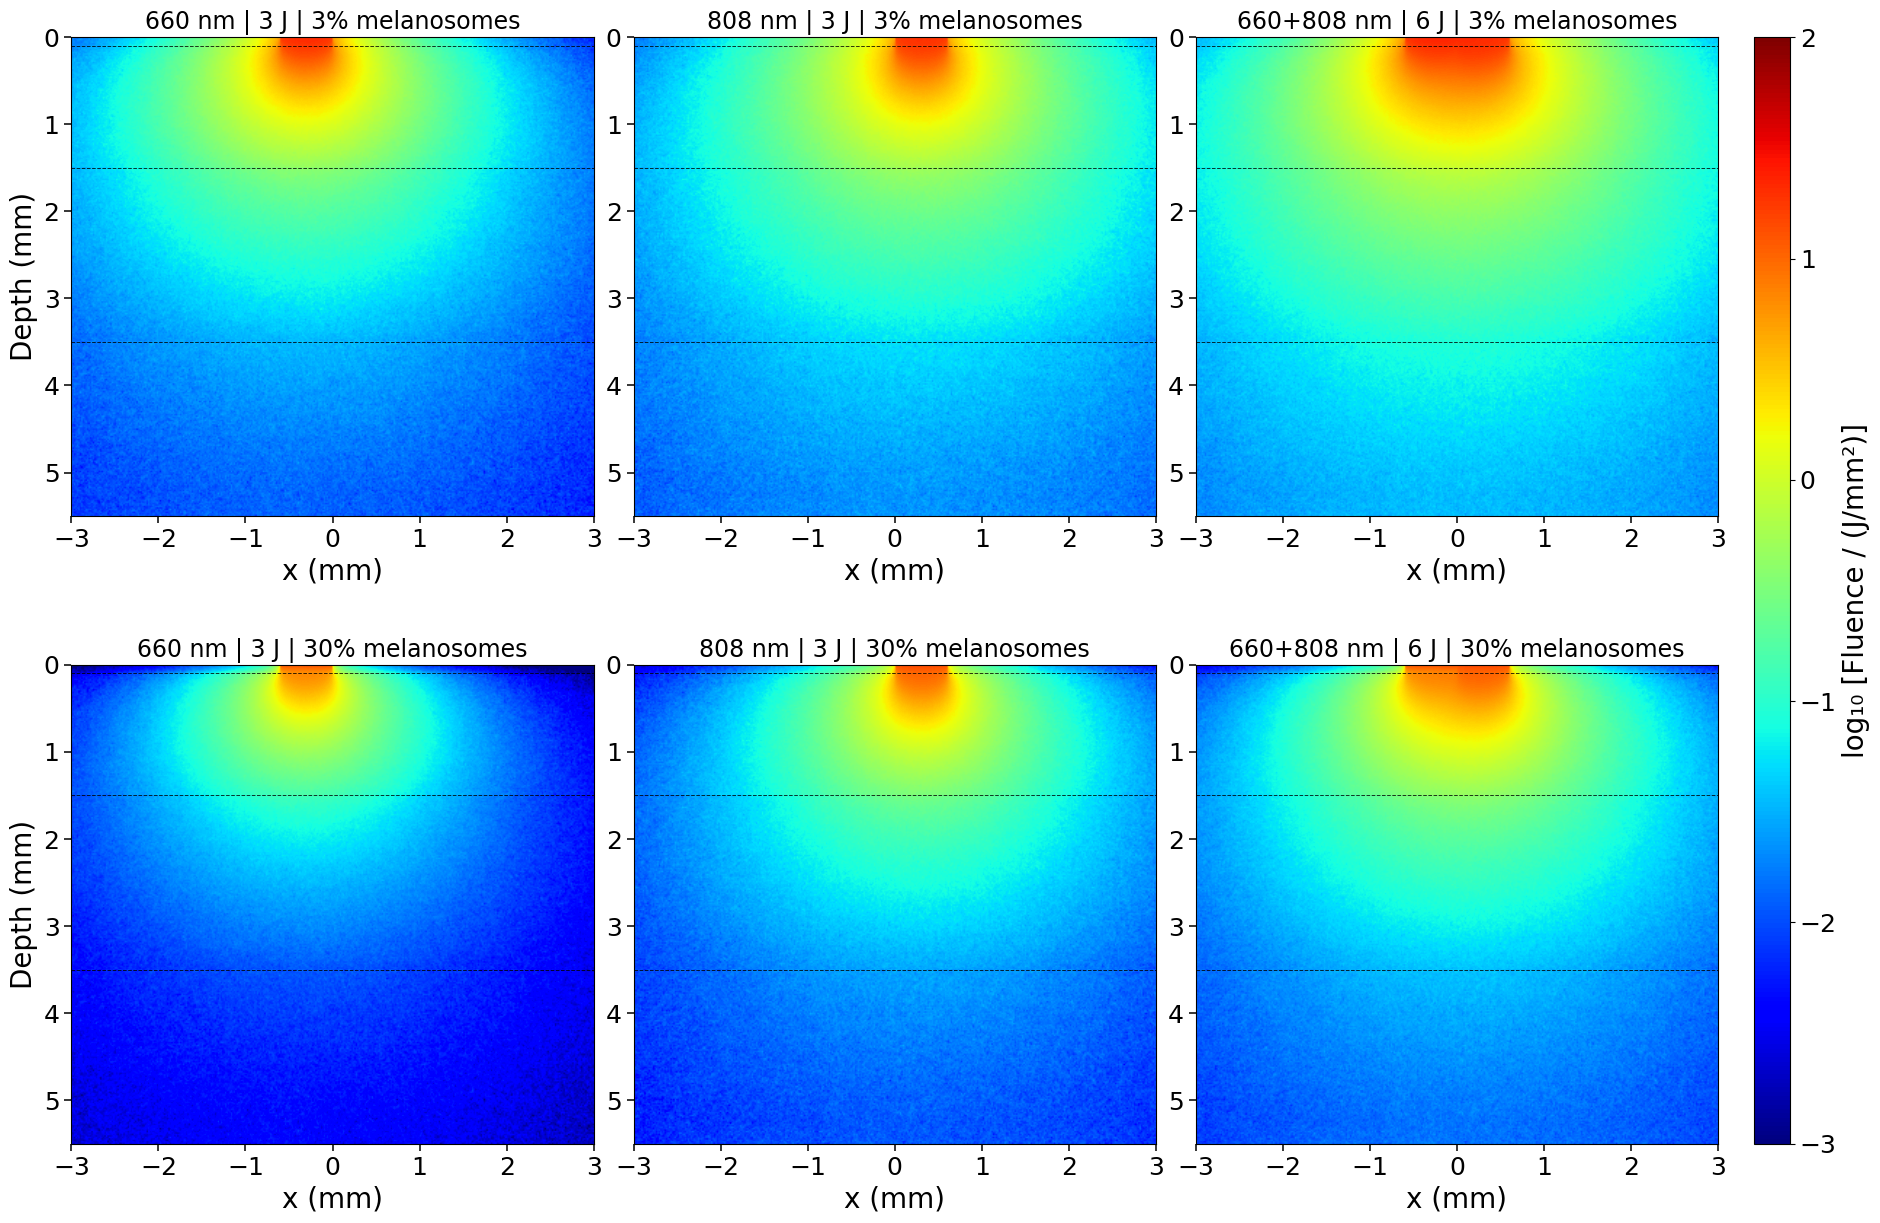

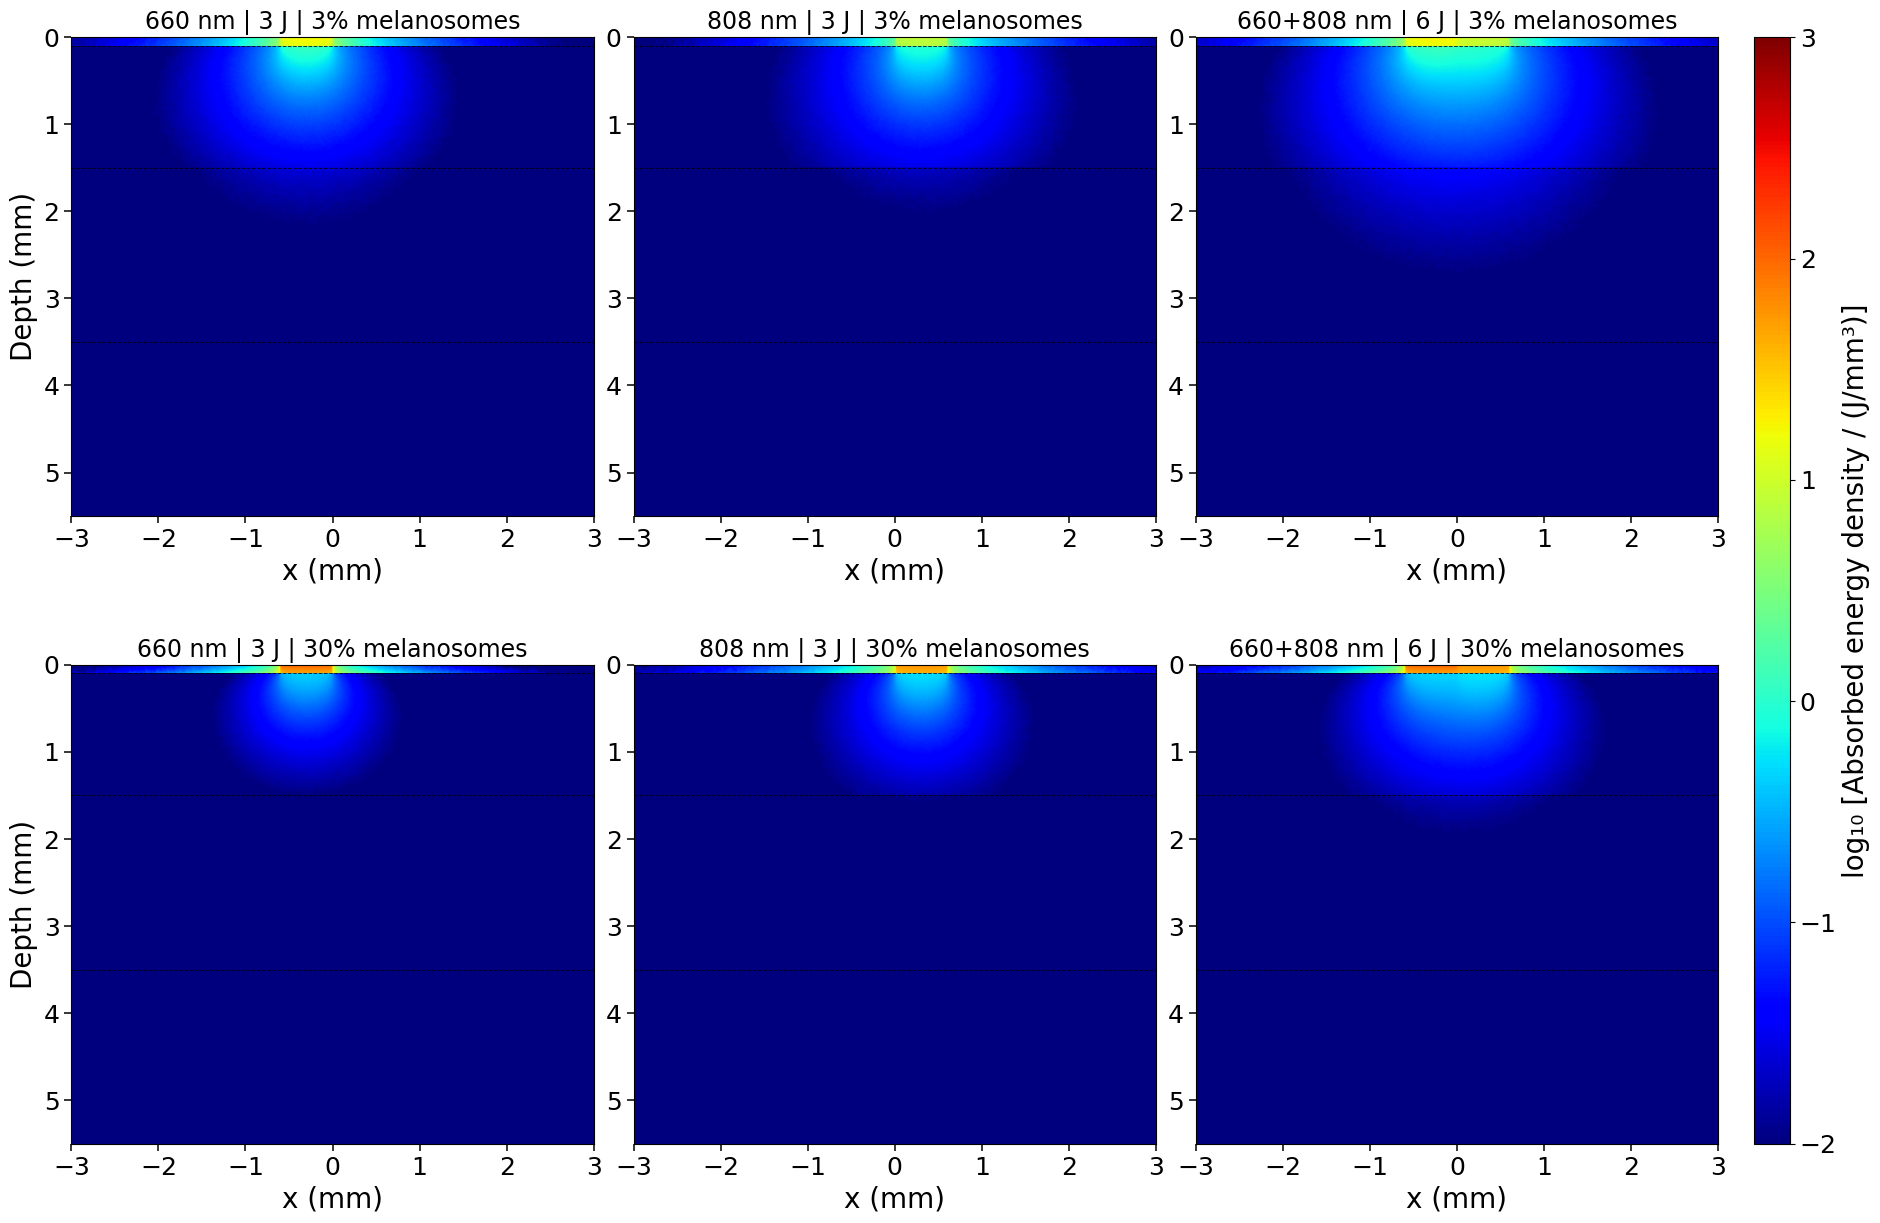

In [10]:

# Perfis contínuos: preserva todos os pontos e os saltos nas interfaces.
def perfil_por_tecido(ax, profundidade, valores, **kwargs):
    valores = np.asarray(valores)
    ax.semilogy(profundidade, np.where(valores > 0, valores, np.nan), **kwargs)
    ax.set_xscale('linear')
    ax.set_xlim(0., float(esp.sum()))
    ax.set_xticks(np.r_[np.arange(0., float(esp.sum()), 1.), float(esp.sum())])
    ax.tick_params(axis='x', labelsize=15, rotation=0)

# Escala linear uniforme em toda a profundidade; coordenadas em mm reais.
BORDAS_REAIS = np.r_[0., np.cumsum(esp)]

def mapa_integrado(ax, lateral, profundidades, valores, lo, hi):
    """Renderização contínua dentro de cada tecido, sem misturar interfaces.
    Interpolação bilinear somente no desenho; não filtra nem altera H/U.
    Coordenadas e espessuras físicas mantidas em mm, aspecto 1:1.
    """
    lateral=np.asarray(lateral); profundidades=np.asarray(profundidades)
    dx=float(lateral[1]-lateral[0])
    bordas=np.r_[0, np.cumsum(nv)]
    for j,(a,b) in enumerate(zip(bordas[:-1],bordas[1:])):
        im=ax.imshow(valores[a:b,:], origin='upper', cmap='jet',
            vmin=lo, vmax=hi, interpolation='bilinear', interpolation_stage='data',
            extent=[lateral[0]-dx/2,lateral[-1]+dx/2,
                    BORDAS_REAIS[j+1],BORDAS_REAIS[j]], aspect='equal', rasterized=True)
    ax.set_ylim(float(esp.sum()),0.)
    ax.set_xlim(lateral[0]-dx/2,lateral[-1]+dx/2)
    # Apenas coordenadas reais; sem nomes de tecidos; interfaces desenhadas abaixo.
    ax.set_xticks(np.arange(-3., 3.01, 1.))
    ax.set_yticks(np.arange(0., np.floor(float(esp.sum()))+1., 1.))
    ax.tick_params(axis='both', labelsize=18, length=5, width=1.1)
    # Interfaces físicas: epiderme/derme/hipoderme/músculo.
    for interface in BORDAS_REAIS[1:-1]:
        ax.axhline(interface, color='black', linestyle='--',
                   linewidth=0.7, alpha=0.8, zorder=10)
    return im


def conferir_cortes(pasta):
    esperados = [
        Path(pasta) / f'd_{SEPARACAO_PRINCIPAL_MM:.3f}mm_{pe}_{p}_corte.npz'
        for pe in PELES
        for p in ['660', '808', '660+808']
    ]

    faltam = [p.name for p in esperados if not p.is_file()]

    if faltam:
        raise FileNotFoundError(
            'Faltam resultados (3% e 30%):\n' + '\n'.join(faltam)
        )

    for p in esperados:
        with np.load(p, allow_pickle=False) as a:
            if 'metadados_json' in a.files:
                meta = json.loads(str(a['metadados_json'].item()))

                energia = (
                    6.
                    if meta['protocolo'] == '660+808'
                    else ENERGIA_ISOLADO_J
                )

                if not (
                    np.isclose(meta['energia_incidente_J'], energia)
                    and np.isclose(meta['area_pele_cm2'], AREA_CM2)
                    and np.isclose(meta['voxel_mm'], VOXEL_MM)
                    and meta['modelo_fonte'] == MODELO_FONTE
                ):
                    raise ValueError(
                        f'{p.name}: configuração incompatível; '
                        'não misture execuções.'
                    )

            else:
                print(
                    'ATENÇÃO: corte antigo sem metadados; '
                    'conferir energia, área e malha:',
                    p.name
                )

            for chave in ['H', 'U', 'media_H', 'media_U', 'energia_camadas']:
                if chave not in a.files:
                    raise ValueError(f'{p.name}: falta {chave}')

                if not np.isfinite(a[chave]).all():
                    raise ValueError(f'{p.name}: {chave} inválido')

    print(
        'Resultados presentes: 3% e 30% × '
        '660, 808 e 660+808 nm = 6 condições.'
    )


# Carrega somente os cortes quando o MCX não foi executado nesta sessão.
if EXECUTAR_SIMULACOES or REFAZER_FIGURAS:
    conferir_cortes(saida)

    if not dados:
        for pe in PELES:
            for p in ['660', '808', '660+808']:
                arquivo = (
                    Path(saida)
                    / f'd_{SEPARACAO_PRINCIPAL_MM:.3f}mm_{pe}_{p}_corte.npz'
                )

                with np.load(arquivo, allow_pickle=False) as a:
                    dados[pe, p] = {
                        k: a[k].copy()
                        for k in [
                            'H',
                            'U',
                            'media_H',
                            'media_U',
                            'energia_camadas',
                            'Eabs'
                        ]
                    }

                    x = a['x_mm'].copy()
                    z = a['z_mm'].copy()

    protocolos = ['660', '808', '660+808']

    campos = [
        ('H', 'J/mm²', 'fluencia', 'Fluence'),
        ('U', 'J/mm³', 'absorcao', 'Absorbed energy density')
    ]

    for campo, unidade, nome, titulo in campos:
        mapas = [
            dados[pe, p][campo][:, 0, :]
            for pe in PELES
            for p in protocolos
        ]

        hi = float(
            np.ceil(
                np.log10(max(float(m.max()) for m in mapas))
            )
        )
        lo = hi - 5

        ix = abs(x) <= 3.

        fig = plt.figure(
            figsize=(20, 13)
        )

        grade = fig.add_gridspec(
            2,
            4,
            width_ratios=[1, 1, 1, .045],
            wspace=.10,
            hspace=.20, left=.065, right=.92, bottom=.075, top=.96
        )

        axes = np.array([
            [fig.add_subplot(grade[i, j]) for j in range(3)]
            for i in range(2)
        ])

        # A barra será alinhada à extensão efetiva dos mapas após aspect='equal'.

        for k, (ax, m) in enumerate(zip(axes.flat, mapas)):
            v = np.log10(np.maximum(m[ix, :].T, 1e-30))

            im = mapa_integrado(
                ax,
                x[ix],
                z,
                v,
                lo,
                hi
            )

            pe = list(PELES)[k // 3]
            p = protocolos[k % 3]
            e = 6. if p == '660+808' else ENERGIA_ISOLADO_J

            ax.set(
                xlabel='x (mm)',
                ylabel='Depth (mm)' if k % 3 == 0 else '',
                title=(
                    f'{p} nm | {e:g} J | '
                    f'{100 * PELES[pe]:g}% melanosomes'
                )
            )

        for ax in axes.flat:
            ax.xaxis.label.set_size(20)
            ax.yaxis.label.set_size(20)
            ax.title.set_fontsize(17)
        fig.canvas.draw()
        topo = axes[0, -1].get_position().y1
        base = axes[-1, -1].get_position().y0
        direita = axes[0, -1].get_position().x1
        cax = fig.add_axes([direita + .018, base, .018, topo-base], label='<colorbar>')
        # Unidade e escala comuns aos seis painéis.
        cb = fig.colorbar(
            im,
            cax=cax,
            label=f'log₁₀ [{titulo} / ({unidade})]'
        )

        cb.ax.tick_params(labelsize=18)
        cb.ax.yaxis.label.set_size(20)

        exportar_figura(
            fig,
            Path(saida) / f'{nome}_corte_lateral.png',
            DPI
        )

        plt.show()
        plt.close(fig)

## 8.1 Perfis físicos
Os perfis mantêm profundidade real, sem expansão visual. U não é temperatura.


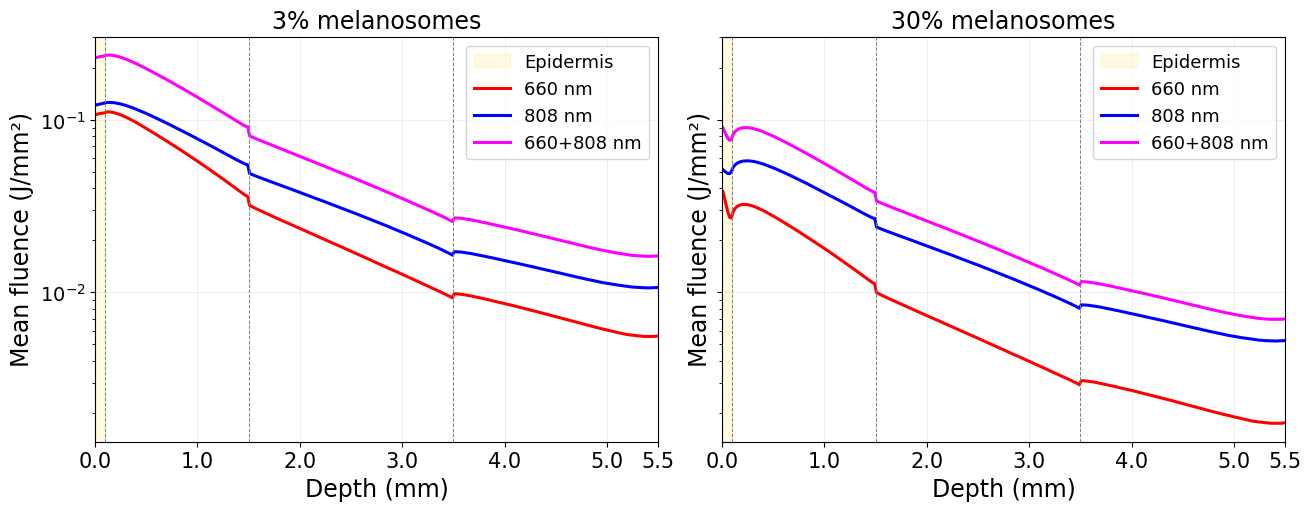

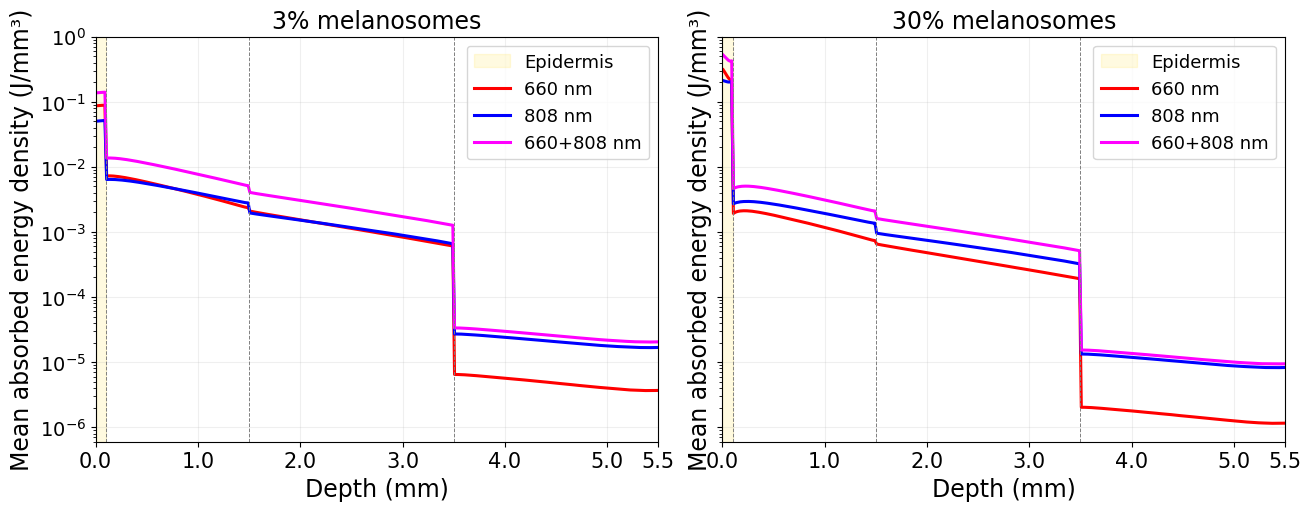

In [11]:
# Visualizações adicionais: dados existentes, sem executar MCX nesta célula.
# O corte XZ passa por uma linha central de voxels em Y.
# Vista lateral no plano XZ, correspondente ao plano y = 0 mm no contínuo.
# Na malha com NY par, o corte usa o centro de voxel mais próximo; não há voxel em y = 0 exato.
# Ampliação e escala local não acrescentam resolução física nem interpolam os dados.
if EXECUTAR_SIMULACOES or REFAZER_FIGURAS:
    protocolos = ['660', '808', '660+808']
    cores = ['red', 'blue', 'magenta']
    def salvar_figura(fig, nome):
        for ext in ['png']:
            exportar_figura(fig, saida / f'{nome}.{ext}', DPI)
        plt.show()
        plt.close(fig)

    # Perfis médios sobre toda a área XY do domínio: mesma definição do gráfico original.
    for campo, unidade, nome, titulo in [
        ('H', 'J/mm²', 'fluencia', 'Mean fluence'),
        ('U', 'J/mm³', 'absorcao', 'Mean absorbed energy density')]:
        for superficial in [False]:
            mascara = z < EPI_MM if superficial else np.ones(len(z), dtype=bool)
            fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', sharey=True)
            for ax, pele in zip(axes, PELES):
                ax.axvspan(0, EPI_MM, color='gold', alpha=.12, label='Epidermis')
                for protocolo, cor in zip(protocolos, cores):
                    valores = dados[(pele, protocolo)]['media_' + campo][mascara]
                    perfil_por_tecido(ax, z[mascara], np.where(valores > 0, valores, np.nan),
                                color=cor, label=protocolo + ' nm',
                                marker='o' if superficial else None, markersize=4)
                for interface in np.cumsum(esp)[:-1]:
                    if not superficial or interface <= EPI_MM:
                        ax.axvline(interface, color='grey', ls='--', lw=.7)
                ax.set(xlabel='Depth (mm)', ylabel=f'{titulo} ({unidade})',
                       title=f'{100*PELES[pele]:g}% melanosomes',
                       xlim=(0, EPI_MM if superficial else float(esp.sum())))
                ax.grid(alpha=.2); ax.legend()
            # A definição da média XY é descrita na legenda externa do pôster.
            salvar_figura(fig, f'perfis_{nome}' + ('_epiderme' if superficial else ''))



## 9 Salvando configuração e baixando o pacote


In [12]:
# Registrar parâmetros e baixar ZIP.
config=dict(energia_isolado_J=ENERGIA_ISOLADO_J,tempo_isolado_s=TEMPO_ISOLADO_S,
    energia_combinado_J=6.,energia_combinado_por_emissao_J=3.,tempo_combinado_s=30.,
    separacoes_hipoteticas_mm=SEPARACOES_MM,area_por_spot_cm2=AREA_CM2,area_conjunta_cm2=AREA_CONJUNTA_CM2,
    espessuras_mm=esp.tolist(),voxel_mm=VOXEL_MM,nphoton=NPHOTON,modelo_termico=False,camadas=CAMADAS,modelo_fonte=MODELO_FONTE,diametro_fonte_mm=2*RAIO_MM,distancia_espacador_mm=DISTANCIA_ESPACADOR_MM,divergencia_total_ar_rad=DIVERGENCIA_TOTAL_AR_RAD if USAR_DIVERGENCIA else 0.,
    areas_protocolos_cm2=AREAS_PROTOCOLOS_CM2,
    pigmentacoes_melanossomos=PELES,
    intersecao_fisica_determinada=False,percurso_ar_simulado=False,
    escala_profundidade_figuras='linear_uniforme_mm_reais_aspect_equal')
(saida/'configuracao.json').write_text(json.dumps(config,indent=2),encoding='utf-8')


1044

## Grandezas e limites
H: fluência em J/mm². U=μaH: densidade de energia absorvida em J/mm³. Não há cálculo de temperatura.
Os arquivos dos isolados contêm os volumes completos; os arquivos _corte.npz contêm apenas cortes centrais. O combinado é obtido pela soma de 3 J de cada emissão.
A convergência da malha, o número de fótons e a influência das fronteiras devem ser avaliados.


## Referências e rastreabilidade
1. **Cassemiro A, Motta LJ, Fiadeiro P, Fonseca E (2024).** Predictive Model of the Effects of Skin Phototype and Body Mass Index on Photobiomodulation Therapy for Orofacial Disorders. *Photonics* 11:1038. DOI [10.3390/photonics11111038](https://doi.org/10.3390/photonics11111038). Simulações em 660/808 nm; equações 2–3/tabela 1 para composição epidérmica; equações 6–7/tabela 2 para μs′, g e n. Tabela 3 transcrita para comparação. 30% é extensão do modelo, não condição simulada pelos autores.
2. **Mignon C et al. (2018).** Shedding light on the variability of optical skin properties. *Biomedical Optics Express* 9:852–872. DOI [10.1364/BOE.9.000852](https://doi.org/10.1364/BOE.9.000852). Seção 2.1: espessuras de 0,100; 1,400; 2,000 mm, conforme literatura anatômica.
3. **Regan C, Hayakawa C, Choi B (2017).** Momentum transfer Monte Carlo for the simulation of laser speckle imaging and its application in the skin. *Biomedical Optics Express* 8:5708–5723. DOI [10.1364/BOE.8.005708](https://doi.org/10.1364/BOE.8.005708). Figura 3: cenários fair=3%, dark=30%; não conversão ITA/Fitzpatrick.
4. **Shimojo Y et al. (2020).** Measurement of absorption and reduced scattering coefficients in Asian human epidermis, dermis, and subcutaneous fat tissues in the 400- to 1100-nm wavelength range for optical penetration depth and energy deposition analysis. *Journal of Biomedical Optics* 25:045002. DOI [10.1117/1.JBO.25.4.045002](https://doi.org/10.1117/1.JBO.25.4.045002). Tabela 3: μa dérmico/adiposo interpolado; μs′ medido fica registrado, sem uso ativo nesta versão. Errata de 2021 refere-se à tabela 2 de sangue.
5. **Jacques SL (2013).** Optical properties of biological tissues: a review. DOI [10.1088/0031-9155/58/11/R37](https://doi.org/10.1088/0031-9155/58/11/R37). Fonte de composição/absorção citada por Cassemiro, preservada como referência de origem.
6. **MCmatlab — biblioteca espectral pública:** [spectralLIB.mat](https://github.com/ankrh/MCmatlab/blob/Release/helperfuncs/spectralLIB.mat). Linhas de 660 e 808 nm transcritas no código, sem dependência de download durante a simulação; arquivo identificado por SHA-256. [OMLC/mcxyz](https://omlc.org/software/mc/mcxyz/index.html) descreve as unidades em cm⁻¹ e os cromóforos. [Tabela textual pública](https://omlc.org/software/mc/mcxyz/spectralLIB.dat) identifica μa,gordura=10⁻⁴ cm⁻¹ como preenchimento onde não havia dados. Não se presume que essa versão pública seja o arquivo exato usado por Cassemiro.
7. **Bashkatov AN, Genina EA, Tuchin VV (2011).** Optical properties of skin, subcutaneous, and muscle tissues: a review. Fonte indireta de g citada por Cassemiro.
8. **DMC — Manual do Usuário Therapy EC**, páginas 5 e 16: núcleo 600 µm, divergência 0,45 ± 0,03 rad. A distância entre centros e a distribuição angular não são medidas neste modelo.
9. **MCX oficial**: https://github.com/fangq/mcx/blob/master/mcxlab/mcxlab.m. `angleinvcdf` fornece a CDF inversa de theta/pi; `disk` define o raio espacial, não a divergência.

### Limites e verificações
Os valores do Word e suas limitações são registrados em origem_valores_Word.txt. Músculo: μa e μs′ calculados conforme Cassemiro. g experimental de Haugen et al. (2023), Dataset 1, Rat Anisotropy, C79 = 0,9480171002957918 em 660 nm e C116 = 0,953797103718739 em 808 nm, medido em ratos; μs = μs′/(1−g). Não se utiliza a equação extrapolada de g muscular. Absorção muscular calculada com HbO2=Hb=0,50 µM e água 70%, usando espectros MCmatlab. Não são medições das suas amostras.

A epiderme permanece com 0,1 mm. Todos os tecidos usam a mesma escala linear de profundidade e proporção física dos eixos, com rótulos físicos em mm. A orientação visual com entrada por cima não altera a propagação.

Para convergência: comparar malhas de 0,025 mm, 0,1/6 mm e 0,0125 mm mantendo dimensões físicas, depois avaliar fótons/sementes e extensão das fronteiras separadamente. O domínio não é infinito e o músculo de 2 mm exige teste de fronteira. A malha padrão tem 118,8 milhões de voxels (600 × 600 × 330), e não deve ser confundida com um aumento apenas de DPI.

Haugen et al. (2023). Measurement of rat and human tissue optical properties for improving the optical detection and visualization of peripheral nerves. https://pmc.ncbi.nlm.nih.gov/articles/PMC10278628/. Dataset 1: https://doi.org/10.6084/m9.figshare.22216954. Anisotropia muscular experimental de ratos; adoção em tecido humano é hipótese entre espécies.


## 10 Figuras selecionadas
Mapas XY de H e U, perfis de H, razão de pigmentação e energia absorvida por camada. Não gera Fresnel, isosuperfícies, métricas por limiar ou cortes adicionais.


Lendo resultados salvos: clara_3pct, 660 nm
Lendo resultados salvos: clara_3pct, 808 nm
Lendo resultados salvos: escura_30pct, 660 nm
Lendo resultados salvos: escura_30pct, 808 nm


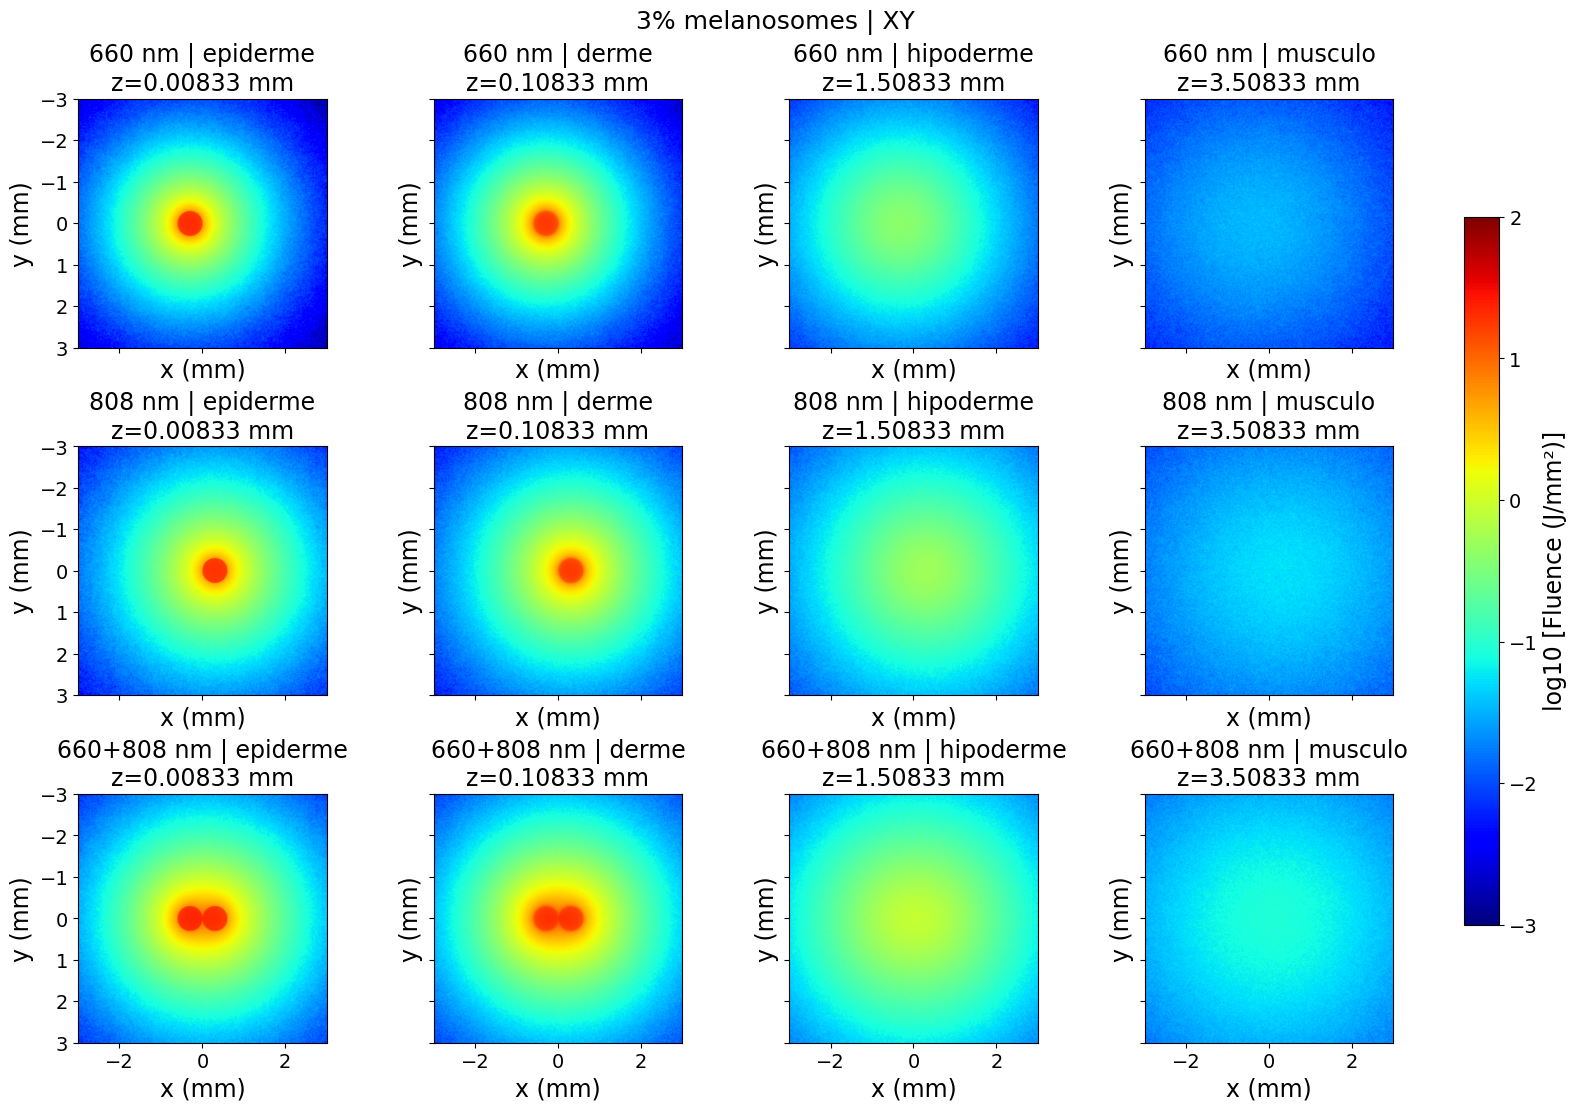

Salvo: H_XY_camadas_clara_3pct


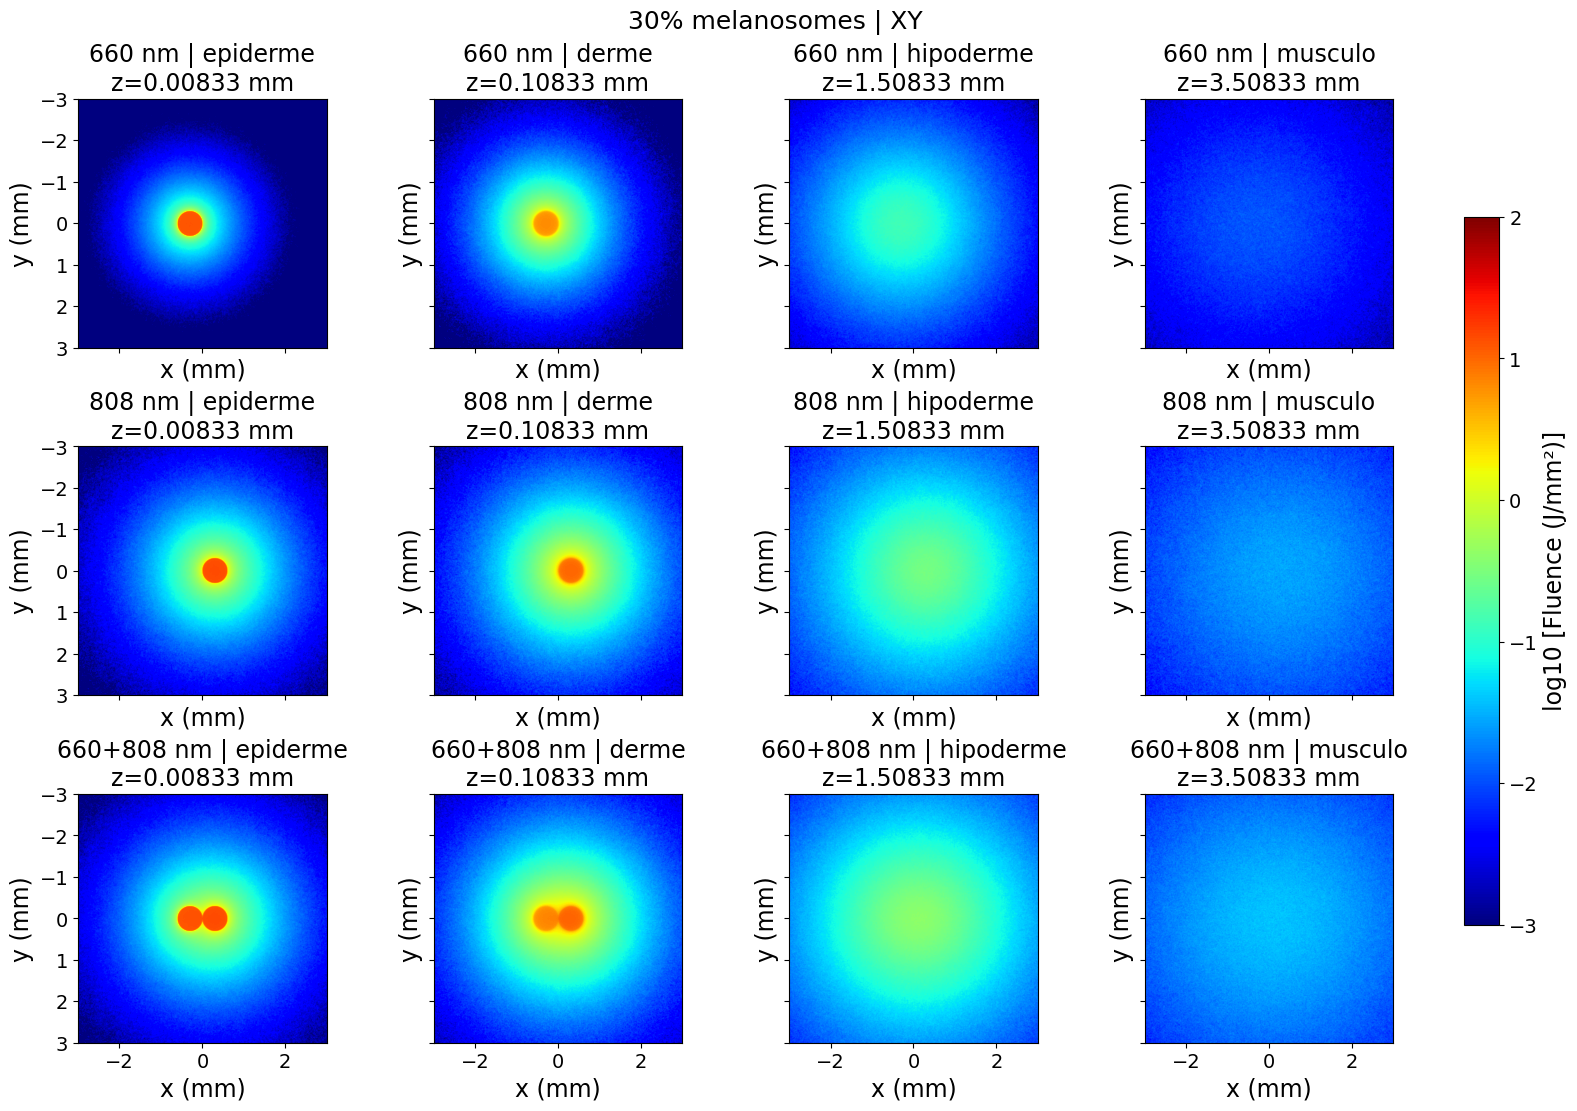

Salvo: H_XY_camadas_escura_30pct


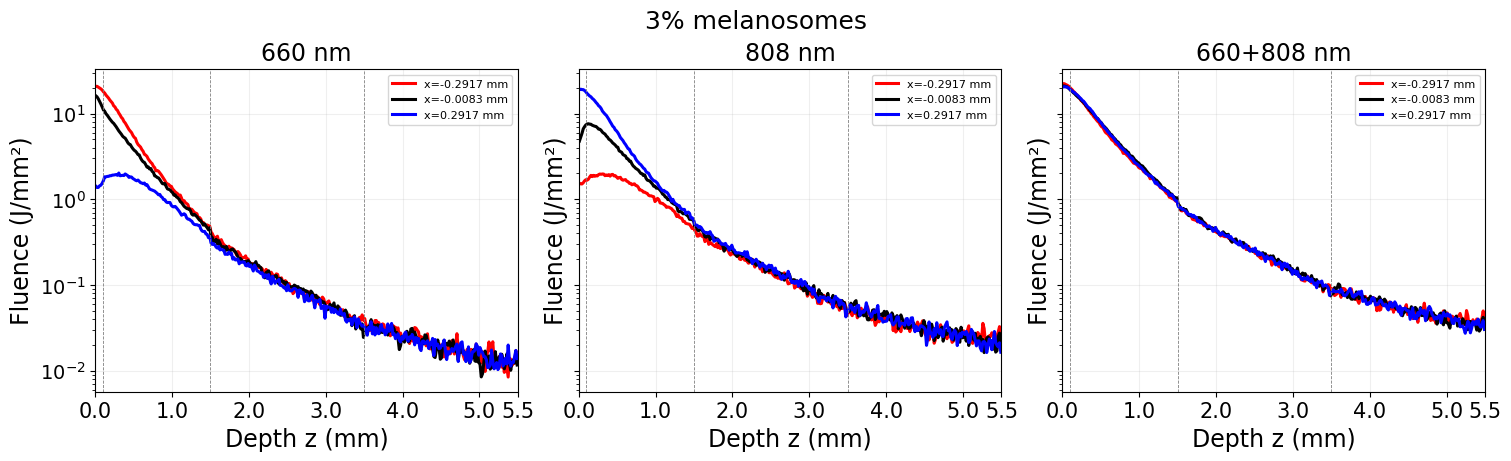

Salvo: H_perfis_profundidade_clara_3pct


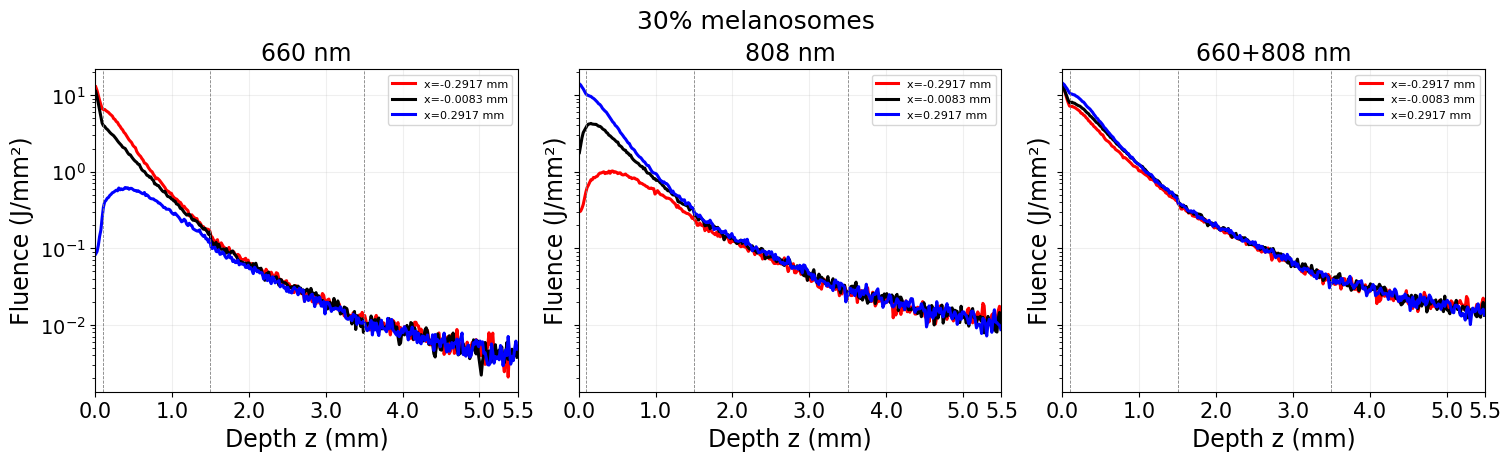

Salvo: H_perfis_profundidade_escura_30pct


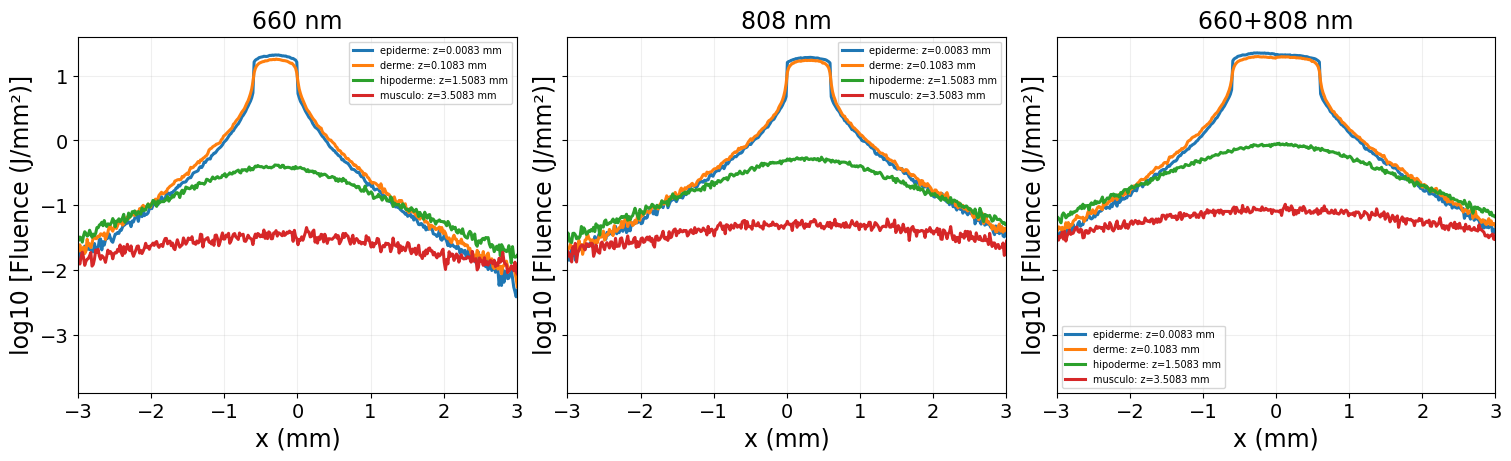

Salvo: H_perfis_laterais_clara_3pct


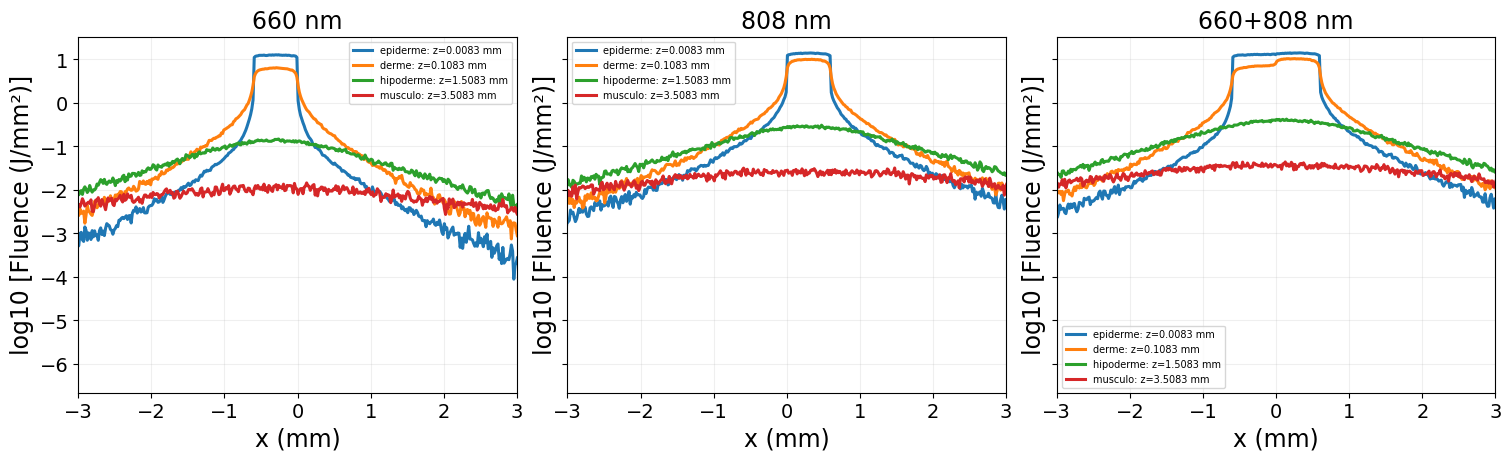

Salvo: H_perfis_laterais_escura_30pct


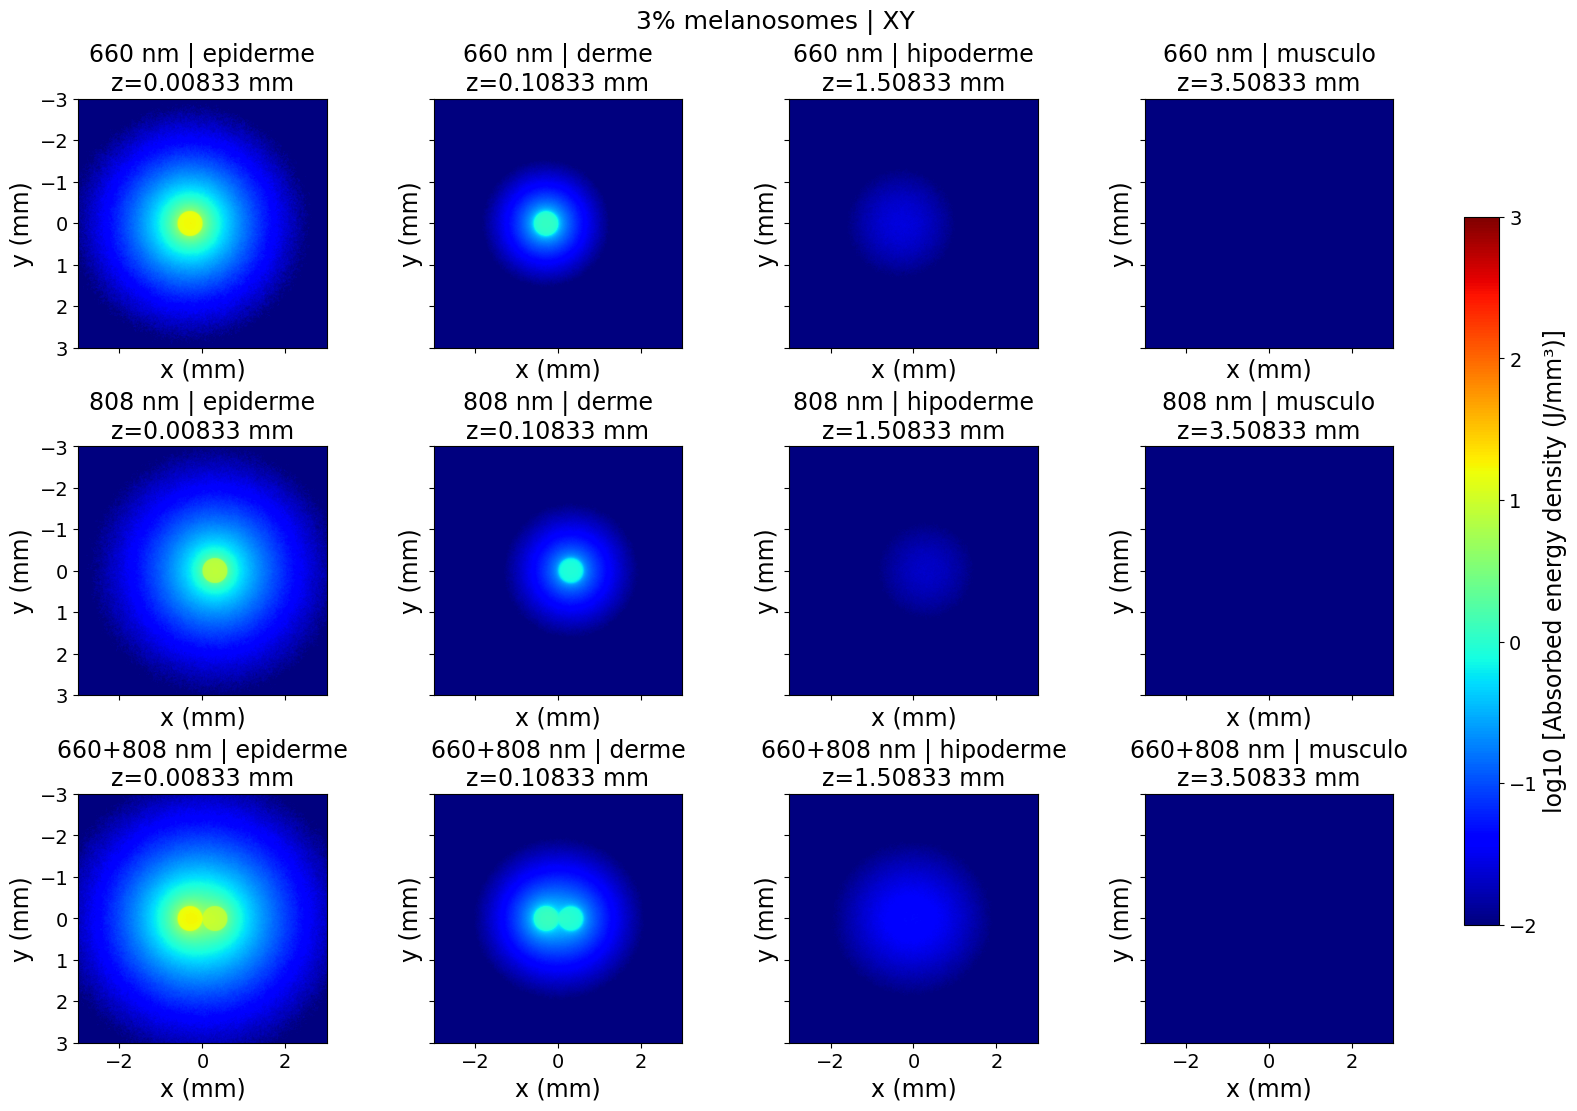

Salvo: U_XY_camadas_clara_3pct


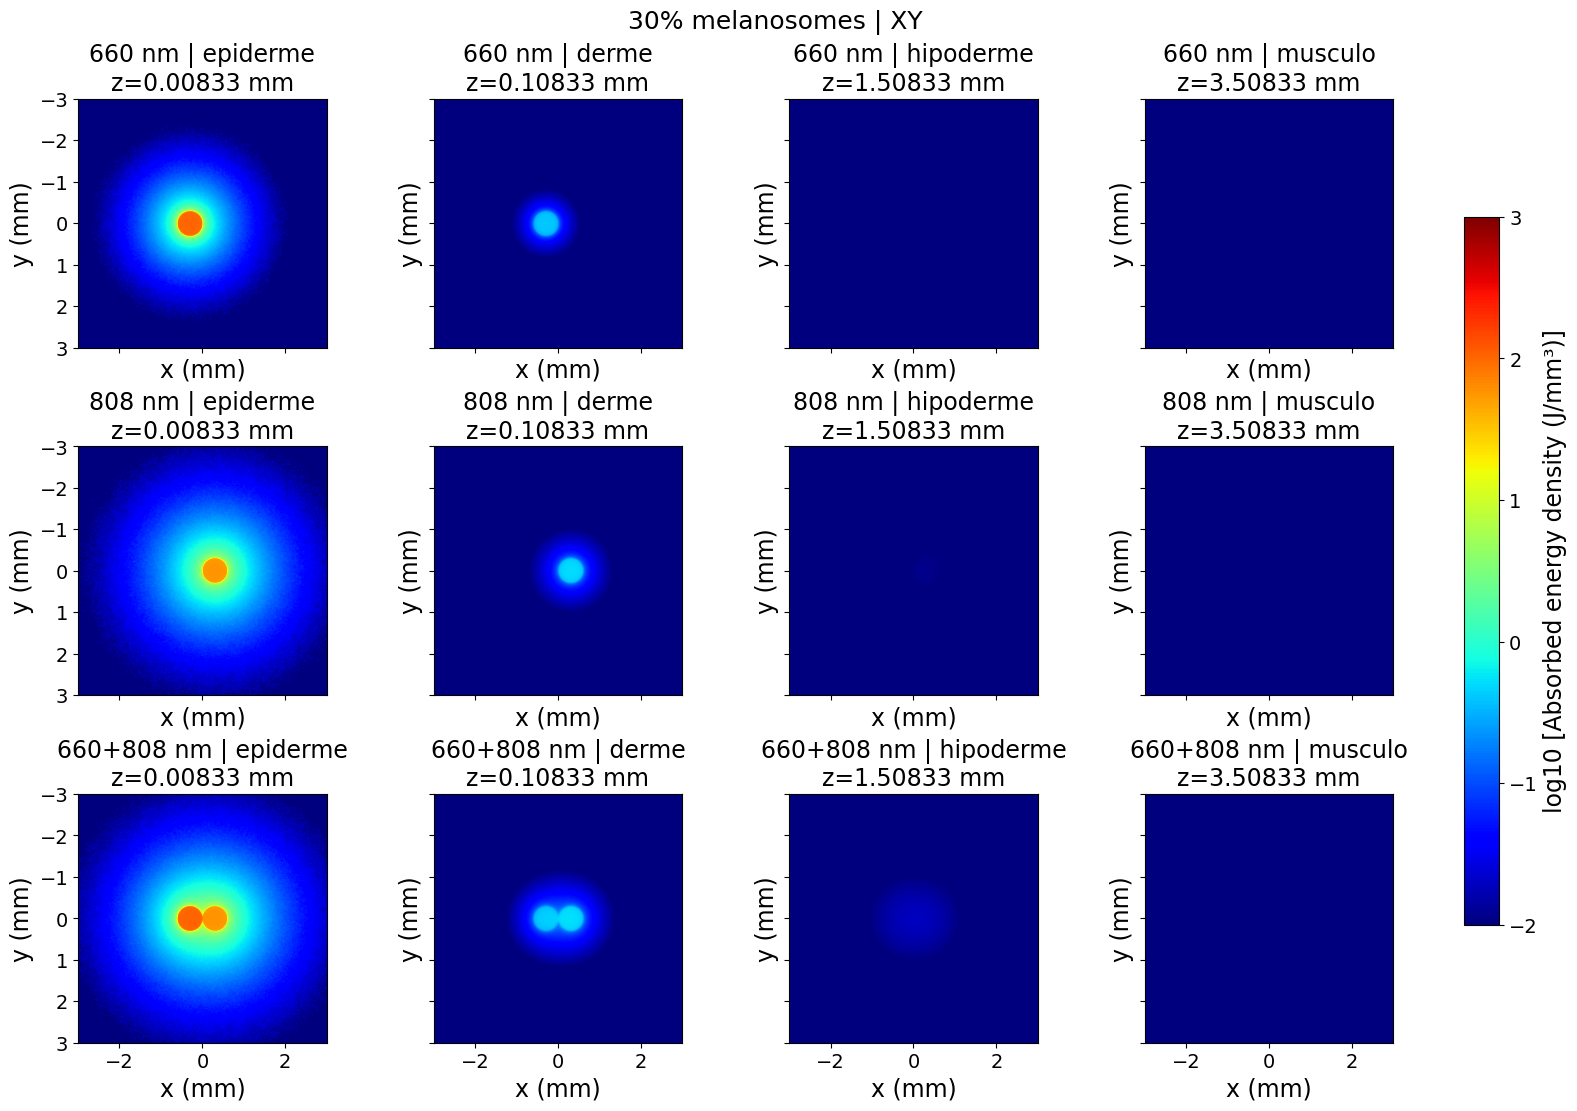

Salvo: U_XY_camadas_escura_30pct


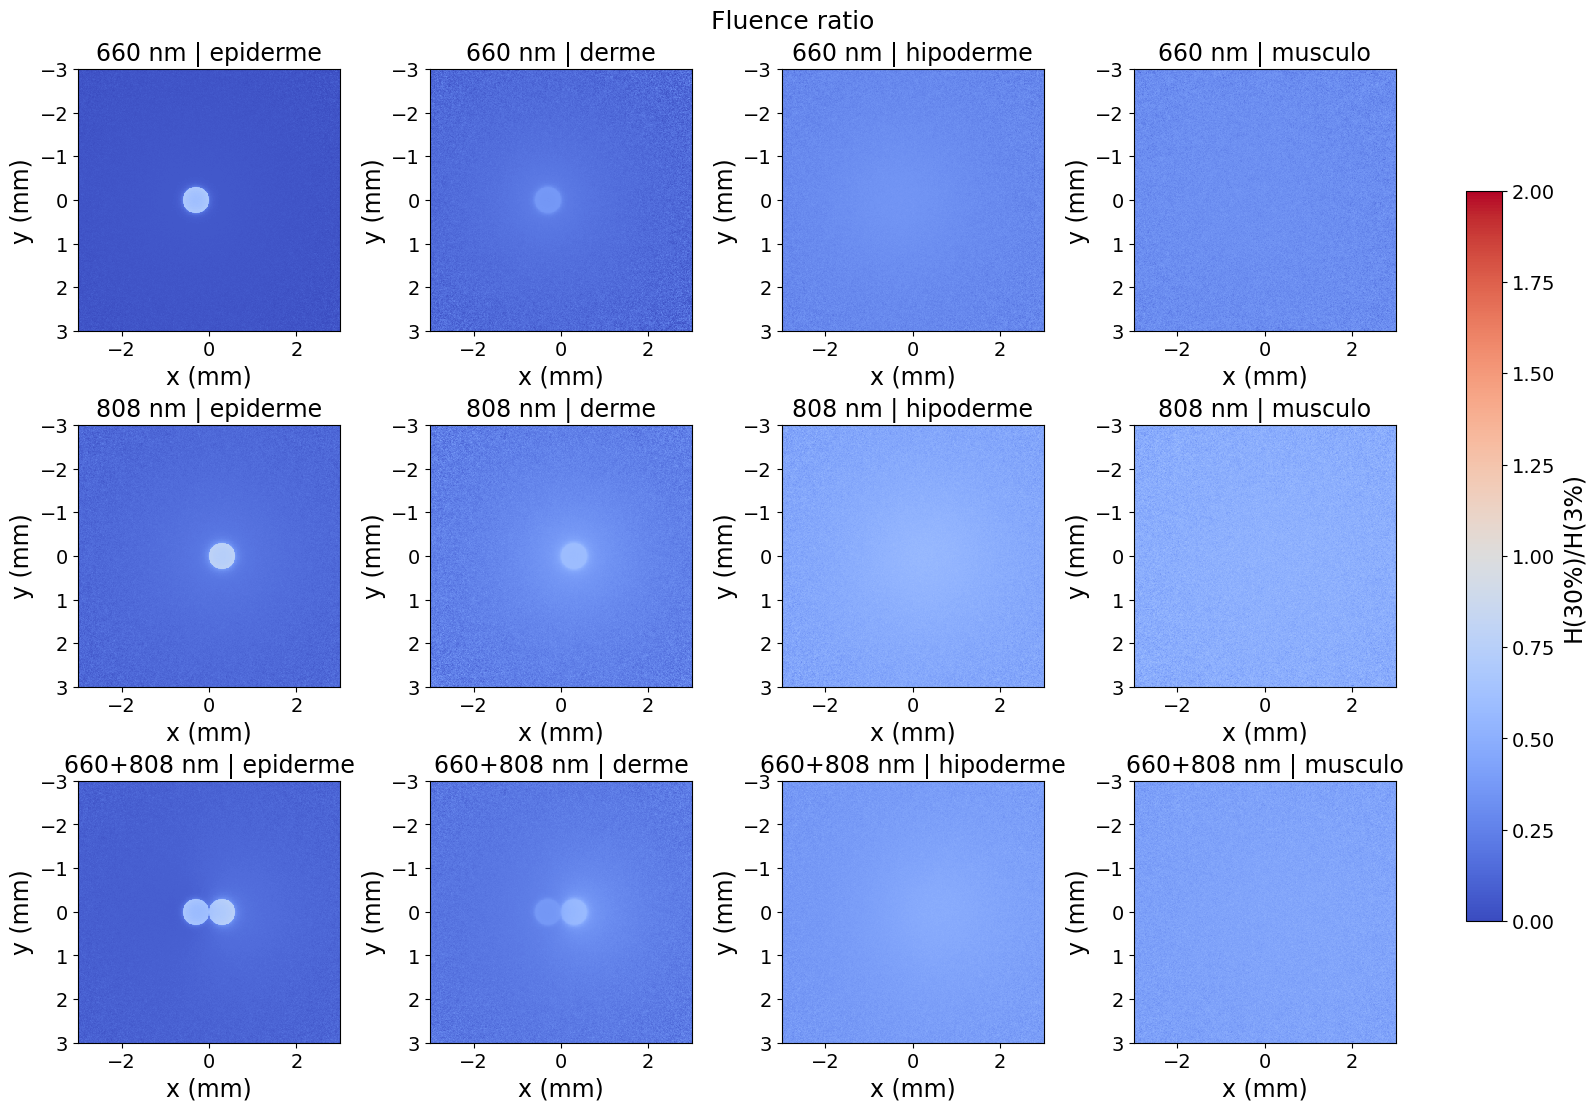

Salvo: H_razao_pigmentacao_XY


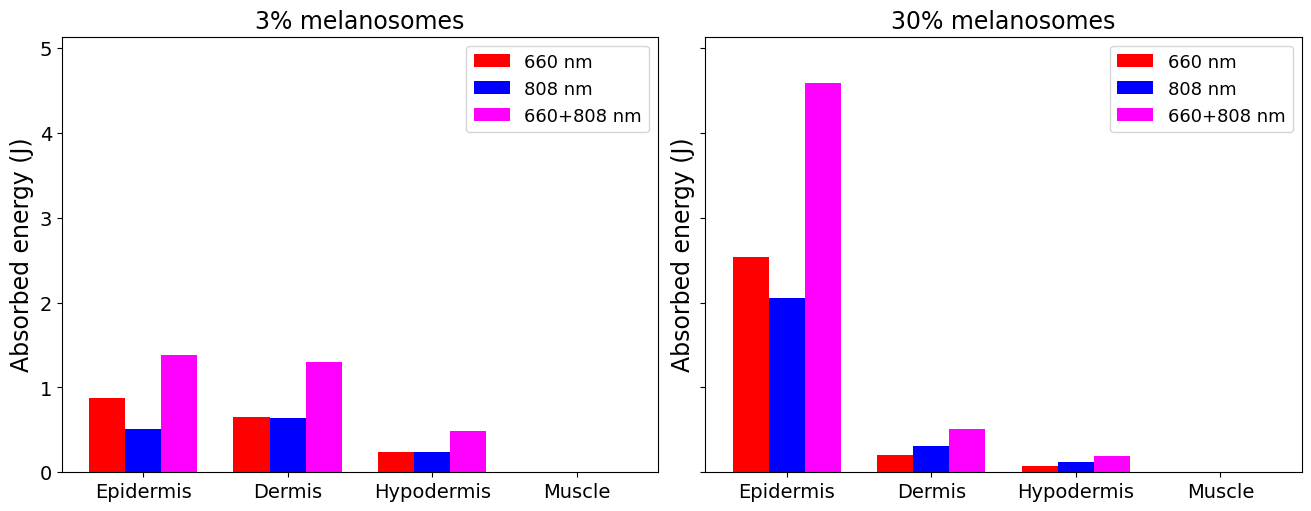

Salvo: energia_absorvida_camadas
CONCLUÍDO. Figuras PNG e tabelas: /content/resultados_MCX_sem_espacador_fibras600um_3J_6J_6mws2eas/graficos_completos


In [13]:
# Executar depois da seção 7. Não chama pmcx.run e não altera os resultados MCX.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import csv, gc

PASTA_GRAFICOS = Path(saida) / 'graficos_completos'
PASTA_GRAFICOS.mkdir(exist_ok=True)
DPI_GRAFICOS = DPI
LIMIAR_LOG10_H = -3.0  # H = 10^-3 J/mm²; escolha de análise, não limiar biológico
PASSO_3D = 4  # subamostragem apenas para visualização da isosuperfície
PROTOCOLOS_T = ['660', '808', '660+808']
CORES_T = ['red', 'blue', 'magenta']
XT = (np.arange(NX)+.5-NX/2)*VOXEL_MM
YT = (np.arange(NY)+.5-NY/2)*VOXEL_MM
ZT = (np.arange(NZ)+.5)*VOXEL_MM
IX0 = int(np.argmin(abs(XT))); IY0 = int(np.argmin(abs(YT)))
inicios_t = np.r_[0., np.cumsum(esp)[:-1]]
# Primeira camada de voxels de cada tecido; profundidades reais aparecem nos títulos.
K_T = np.rint(inicios_t/VOXEL_MM).astype(int)
DT = {}; ESTAT_T = []

faltantes_t=[str(Path(saida)/f'd_{SEPARACAO_PRINCIPAL_MM:.3f}mm_{pe}_{lam}nm.npz')
              for pe in PELES for lam in [660,808]
              if not (Path(saida)/f'd_{SEPARACAO_PRINCIPAL_MM:.3f}mm_{pe}_{lam}nm.npz').is_file()]
if faltantes_t: raise FileNotFoundError('Volumes ausentes (3%/30%):\n'+'\n'.join(faltantes_t))
# Cache leve: cortes, perfis e volume subamostrado para o desenho 3D.
for pele in PELES:
    for lam in [660,808]:
        arquivo = Path(saida)/f'd_{SEPARACAO_PRINCIPAL_MM:.3f}mm_{pele}_{lam}nm.npz'
        print(f'Lendo resultados salvos: {pele}, {lam} nm', flush=True)
        with np.load(arquivo, allow_pickle=False) as arq:
            propriedades = arq['propriedades'] if 'propriedades' in arq.files else None
            if 'metadados_json' in arq.files:
                import json
                mt = json.loads(str(arq['metadados_json'].item()))
                if not np.isclose(mt['energia_incidente_J'],ENERGIA_ISOLADO_J):
                    raise ValueError('Energia dos arquivos diferente da configuração atual.')
                if not np.isclose(mt['voxel_mm'],VOXEL_MM):
                    raise ValueError('Voxel dos arquivos diferente da configuração atual.')
                if not np.isclose(mt.get('area_fonte_modelo_cm2',-1),AREA_CM2) or mt.get('modelo_fonte')!=MODELO_FONTE:
                    raise ValueError('Área ou modelo de fonte incompatível com os volumes.')
                if not np.isclose(mt.get('distancia_espacador_mm',-1),DISTANCIA_ESPACADOR_MM):
                    raise ValueError('Espaçador dos arquivos diferente da configuração atual.')
            for campo,chave in [('H','fluencia_J_mm2'),('U','energia_absorvida_J_mm3')]:
                v = arq[chave]
                if v.shape != (NX,NY,NZ):raise ValueError('Malha incompatível com os arquivos salvos.')
                DT[pele,str(lam),campo] = dict(
                    xz=v[:,IY0,:].copy(), yz=v[IX0,:,:].copy(),
                    xy=np.stack([v[:,:,k] for k in K_T]),
                    media=v.mean((0,1),dtype=np.float64),
                    pequeno=None)
                if campo=='U':
                    bordas=np.r_[K_T,NZ]
                    energias=[float(v[:,:,a:b].sum(dtype=np.float64)*VOXEL_MM**3)
                              for a,b in zip(bordas[:-1],bordas[1:])]
                    DT[pele,str(lam),'energias']=np.array(energias)
                del v;gc.collect()
        del propriedades
    fator_t=3./ENERGIA_ISOLADO_J
    for campo in ['H','U']:
        DT[pele,'660+808',campo]={k:(DT[pele,'660',campo][k]+DT[pele,'808',campo][k])*fator_t
                                if DT[pele,'660',campo][k] is not None else None
                                for k in DT[pele,'660',campo]}
    DT[pele,'660+808','energias']=(DT[pele,'660','energias']+DT[pele,'808','energias'])*fator_t

plt.rcParams.update({'font.size':15,'axes.titlesize':17,'axes.labelsize':17})
def gravar_t(fig,nome):
    exportar_figura(fig, PASTA_GRAFICOS/(nome+'.png'), DPI_GRAFICOS)
    plt.show();plt.close(fig)
    print('Salvo:',nome,flush=True)

def log_t(v):return np.log10(np.maximum(v,1e-30))
def niveis_t(v,lo,hi):
    return [l for l in np.arange(lo,hi+.01,.5) if v.min()<l<v.max()]
def interfaces_t(ax,prof):
    for z0 in np.cumsum(esp)[:-1]:
        if z0<prof:ax.axhline(z0,color='white',ls='--',lw=.7)

for campo,unidade,rotulo in [('H','J/mm²','Fluence'),('U','J/mm³','Absorbed energy density')]:
    hi=float(np.ceil(np.log10(max(DT[pe,p,campo]['xz'].max() for pe in PELES for p in PROTOCOLOS_T))))
    lo=hi-5
    for pe in PELES:
        fig,axes=plt.subplots(3,len(K_T),figsize=(16,11),squeeze=False,layout='constrained',sharex=True,sharey=True)
        it=abs(XT)<=3.;jt=abs(YT)<=3.
        for i,p in enumerate(PROTOCOLOS_T):
            for j,k in enumerate(K_T):
                ax=axes[i,j];v=log_t(DT[pe,p,campo]['xy'][j][np.ix_(it,jt)].T)
                im=ax.imshow(v,origin='upper',cmap='jet',vmin=lo,vmax=hi,interpolation='bilinear',interpolation_stage='data',aspect='equal',
                    extent=[XT[it][0]-VOXEL_MM/2,XT[it][-1]+VOXEL_MM/2,YT[jt][-1]+VOXEL_MM/2,YT[jt][0]-VOXEL_MM/2])
                ax.set(xlabel='x (mm)',ylabel='y (mm)',title=f'{p} nm | {CAMADAS[j]}\nz={ZT[k]:.5f} mm')
        fig.colorbar(im,ax=list(axes.flat),shrink=.75,label=f'log10 [{rotulo} ({unidade})]')
        fig.suptitle(f'{100*PELES[pe]:g}% melanosomes | XY')
        gravar_t(fig,f'{campo}_XY_camadas_{pe}')
    for pe in (PELES if campo=='H' else []):
        fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained',sharey=True)
        for ax,p in zip(axes,PROTOCOLOS_T):
            for alvo,cor in zip([-SEPARACAO_PRINCIPAL_MM/2,0.,SEPARACAO_PRINCIPAL_MM/2],['red','black','blue']):
                k=int(np.argmin(abs(XT-alvo)));v=DT[pe,p,campo]['xz'][k]
                perfil_por_tecido(ax, ZT,np.where(v>0,v,np.nan),color=cor,label=f'x={XT[k]:.4f} mm')
            for z0 in np.cumsum(esp)[:-1]:ax.axvline(z0,color='grey',ls='--',lw=.6)
            ax.set(xlabel='Depth z (mm)',ylabel=f'{rotulo} ({unidade})',title=p+' nm');ax.legend(fontsize=8);ax.grid(alpha=.2)
        fig.suptitle(f'{100*PELES[pe]:g}% melanosomes')
        gravar_t(fig,f'{campo}_perfis_profundidade_{pe}')
    # Perfil lateral em profundidades selecionadas.
    for pe in (PELES if campo=='H' else []):
        fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained',sharey=True)
        linhas=[]
        for ax,p in zip(axes,PROTOCOLOS_T):
            for j,k in enumerate(K_T):
                v=DT[pe,p,campo]['xy'][j,:,IY0]
                ax.plot(XT,log_t(v),label=f'{CAMADAS[j]}: z={ZT[k]:.4f} mm')
                linhas.extend((p,CAMADAS[j],ZT[k],xx,vv) for xx,vv in zip(XT,v))
            ax.set(xlim=(-3,3),xlabel='x (mm)',ylabel=f'log10 [{rotulo} ({unidade})]',title=p+' nm');ax.legend(fontsize=7);ax.grid(alpha=.2)
        gravar_t(fig,f'{campo}_perfis_laterais_{pe}')
        with (PASTA_GRAFICOS/f'{campo}_perfis_laterais_{pe}.csv').open('w',newline='',encoding='utf-8-sig') as f:
            w=csv.writer(f);w.writerow(['protocol','layer','depth_mm','x_mm',campo+'_'+unidade]);w.writerows(linhas)

peles=list(PELES)
if len(peles)==2:
    pe0,pe1=peles
    fig,axes=plt.subplots(3,len(K_T),figsize=(16,11),layout='constrained')
    for i,p in enumerate(PROTOCOLOS_T):
        for j,k in enumerate(K_T):
            den=DT[pe0,p,'H']['xy'][j];num=DT[pe1,p,'H']['xy'][j]
            mascara=den>den.max()*1e-5
            razao=np.full_like(den,np.nan);np.divide(num,den,out=razao,where=mascara)
            ax=axes[i,j];im=ax.imshow(razao.T,origin='upper',extent=[XT[0],XT[-1],YT[-1],YT[0]],
                cmap='coolwarm',vmin=0,vmax=2,aspect='equal',interpolation='nearest')
            ax.set(xlim=(-3,3),ylim=(3,-3),xlabel='x (mm)',ylabel='y (mm)',title=f'{p} nm | {CAMADAS[j]}')
    fig.colorbar(im,ax=list(axes.flat),shrink=.75,label='H(30%)/H(3%)')
    fig.suptitle('Fluence ratio')
    gravar_t(fig,'H_razao_pigmentacao_XY')
# Energia absorvida por camada.
pico_energia=max(float(np.max(DT[pe,p,'energias'])) for pe in PELES for p in PROTOCOLOS_T)
fig,axes=plt.subplots(1,len(PELES),figsize=(13,5),squeeze=False,sharey=True,layout='constrained')
for ax,pe in zip(axes.flat,PELES):
    for i,(p,cor) in enumerate(zip(PROTOCOLOS_T,CORES_T)):
        ax.bar(np.arange(len(CAMADAS))+(i-1)*.25,DT[pe,p,'energias'],width=.25,color=cor,label=p+' nm')
    ax.set(xticks=np.arange(len(CAMADAS)),xticklabels=['Epidermis','Dermis','Hypodermis','Muscle'],ylim=(0,max(pico_energia*1.12,1e-12)),ylabel='Absorbed energy (J)',title=f'{100*PELES[pe]:g}% melanosomes');ax.legend()
gravar_t(fig,'energia_absorvida_camadas')
print('CONCLUÍDO. Figuras PNG e tabelas:',PASTA_GRAFICOS.resolve(),flush=True)


In [14]:

# Exportação bruta (sem log10, sem piso, sem recorte) para Origin.
pasta_raw=Path(saida)/'Origin'/'campos_brutos';pasta_raw.mkdir(parents=True,exist_ok=True)
def matriz_bruta(nome,xx,yy,v):
    m=np.empty((len(yy)+1,len(xx)+1));m[0,0]=np.nan;m[0,1:]=xx;m[1:,0]=yy;m[1:,1:]=v
    np.savetxt(pasta_raw/(nome+'.txt'),m,delimiter='\t',fmt='%.17g')
for pe in PELES:
    for p in PROTOCOLOS_T:
        for campo in ['H','U']:
            r=DT[pe,p,campo];base=f'{pe}_{p}_{campo}'
            matriz_bruta(base+'_XZ',XT,ZT,r['xz'].T)
            for j,k in enumerate(K_T):
                matriz_bruta(base+f'_XY_camada_{j+1}_z_{ZT[k]:.5f}mm',XT,YT,r['xy'][j].T)
            np.savetxt(pasta_raw/(base+'_media_XY.csv'),np.column_stack([ZT,r['media']]),
                       delimiter=',',header='z_mm,'+('H_J_mm2' if campo=='H' else 'U_J_mm3'),comments='',fmt='%.17g')
# Tabela categórica para refazer as barras, sem depender da posição gráfica.
with (pasta_raw/'energia_absorvida_camadas.csv').open('w',newline='',encoding='utf-8-sig') as f:
    w=csv.writer(f);w.writerow(['pele','protocolo_nm','camada','energia_absorvida_J'])
    for pe in PELES:
        for p in PROTOCOLOS_T:
            w.writerows((pe,p,cam,float(e)) for cam,e in zip(CAMADAS,DT[pe,p,'energias']))
(Path(saida)/'Origin'/'LEIA_ME.txt').write_text(
    'CSV: curvas X,Y; importar como colunas. TXT: matrizes com coordenadas; primeira linha X, primeira coluna Y/profundidade, canto NaN. '
    'Configure essas bordas como coordenadas, não como dados. Cada pasta corresponde a uma figura; painéis.json contém títulos, unidades e escalas. '
    'campos_brutos: H em J/mm² e U em J/mm³, sem piso e sem log10. Nos mapas desenhados há log10(max(campo,1e-30)); '
    'inverso_log10 contém esse piso visual. As curvas laterais H têm Y=log10(H); as curvas de profundidade H têm Y físico em eixo logarítmico. '
    'Razão H(30%)/H(3%) é adimensional, com NaN onde a máscara do código exclui o denominador. '
    'volume_simulado contém IDs 1 epiderme, 2 derme, 3 hipoderme, 4 músculo. '
    'Os mapas XY representam a primeira camada de voxels de cada tecido, não a média do tecido. '
    'Os dados de cada linha auxiliar de interface também são exportados; consultar rótulos no JSON. '
    'CSV/TXT são dados editáveis, não arquivos de projeto OPJU. Não há cálculo de temperatura.',encoding='utf-8')
print('Exportação Origin concluída.')


Exportação Origin concluída.


In [15]:
# Tabelas adicionais — usa somente resultados desta execução.
pasta_tabelas = Path(saida) / 'tabelas_salvas'
pasta_tabelas.mkdir(exist_ok=True)
def salvar_registros_tabela(nome, registros):
    if not isinstance(registros, (list, tuple)) or not registros:
        return
    if not all(isinstance(r, dict) for r in registros):
        return
    colunas = list(dict.fromkeys(chave for r in registros for chave in r))
    with (pasta_tabelas/nome).open('w', newline='', encoding='utf-8-sig') as arq:
        w = csv.DictWriter(arq, fieldnames=colunas)
        w.writeheader(); w.writerows(registros)
for variavel in ['resumo', 'linhas_camadas', 'ESTAT_T']:
    salvar_registros_tabela(variavel+'.csv', globals().get(variavel))
registros_energia = []
for pe in PELES:
    for protocolo in ['660', '808', '660+808']:
        energias = DT[pe, protocolo, 'energias']
        incidente = 6. if protocolo == '660+808' else ENERGIA_ISOLADO_J
        for camada, energia in zip(CAMADAS, energias):
            registros_energia.append(dict(
                pele=pe, protocolo_nm=protocolo, camada=camada,
                energia_incidente_J=incidente, energia_absorvida_J=float(energia),
                porcentagem_da_energia_incidente=100.*float(energia)/incidente))
salvar_registros_tabela('energia_absorvida_por_camada.csv', registros_energia)
print('Tabelas salvas em:', pasta_tabelas)


Tabelas salvas em: /content/resultados_MCX_sem_espacador_fibras600um_3J_6J_6mws2eas/tabelas_salvas


In [16]:
from zipfile import ZipFile, ZIP_DEFLATED
permitidas=set(['absorcao_corte_lateral', 'energia_absorvida_camadas', 'fluencia_corte_lateral', 'geometria_spots', 'H_perfis_laterais_clara_3pct', 'H_perfis_laterais_escura_30pct', 'H_perfis_profundidade_clara_3pct', 'H_perfis_profundidade_escura_30pct', 'H_razao_pigmentacao_XY', 'H_XY_camadas_clara_3pct', 'H_XY_camadas_escura_30pct', 'perfis_absorcao', 'perfis_fluencia', 'U_XY_camadas_clara_3pct', 'U_XY_camadas_escura_30pct', 'volume_simulado'])
assert len(permitidas) == 16
pngs = list(Path(saida).rglob('*.png'))
nomes = [p.stem for p in pngs]
if len(pngs) != 16 or set(nomes) != permitidas or FIGURAS_GERADAS != permitidas:
    raise RuntimeError(f'Esperadas 16 figuras únicas. Obtidas {len(pngs)}. Faltam: {permitidas-set(nomes)}; extras: {set(nomes)-permitidas}')
(saida/'lista_16_figuras.json').write_text(json.dumps(sorted(str(p.relative_to(saida)) for p in pngs), indent=2), encoding='utf-8')
zip_path=Path(str(saida)+'_figuras_tabelas.zip')
with ZipFile(zip_path,'w',ZIP_DEFLATED) as zf:
    for arquivo in sorted(Path(saida).rglob('*')):
        if not arquivo.is_file():continue
        rel=arquivo.relative_to(saida)
        if arquivo.suffix=='.png' and arquivo.stem in permitidas or rel.parts[0] in ['Origin', 'tabelas_salvas'] or (len(rel.parts)==1 and arquivo.suffix in ['.csv','.json']):
            zf.write(arquivo,rel)
with ZipFile(zip_path) as zf:
    assert len([p for p in zf.namelist() if p.endswith('.png')]) == 16
print('Pacote: 16 figuras selecionadas e dados para Origin:',zip_path)
# Pacote separado com todas as tabelas CSV/TXT/JSON.
zip_tabelas = Path(str(saida)+'_TABELAS.zip')
with ZipFile(zip_tabelas, 'w', ZIP_DEFLATED) as zf:
    for arquivo in sorted(Path(saida).rglob('*')):
        if arquivo.is_file() and arquivo.suffix.lower() in ['.csv', '.txt', '.json']:
            zf.write(arquivo, arquivo.relative_to(saida))
print('Pacote separado de tabelas:', zip_tabelas)
try:
    from google.colab import files
    files.download(str(zip_path))
    files.download(str(zip_tabelas))
except ImportError:
    print(zip_path.resolve())


Pacote: 16 figuras selecionadas e dados para Origin: /content/resultados_MCX_sem_espacador_fibras600um_3J_6J_6mws2eas_figuras_tabelas.zip
Pacote separado de tabelas: /content/resultados_MCX_sem_espacador_fibras600um_3J_6J_6mws2eas_TABELAS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>